# The 2μ2e background from the search plane's own sidebands

**Summary.** The 2μ2e search region holds an estimated **46 ± 15 (stat.) ± 9 (syst.)** background events
(2018 data, 59.8 fb⁻¹). The estimate is the plain ABCD method in the search plane itself: the
background in the search region, A, is predicted from the three neighbouring regions B, C and D of
the same plane as A = B·C/D = 45.7 ± 14.9 events (from 78, 17 and 29 events). That prediction is
right when the two variables that define the regions are independent for the background. We test
this in every region of the data where the corresponding A is open (not blinded): the three planes
in which at least one lepton jet is prompt; the search plane itself below 150 GeV and, above
150 GeV, in four bands of the egamma lepton jet's isolation outside the search region; and the
seven validation regions of Dongyub Lee's programme, recomputed from these histograms. His regions
test the method on populations with a prompt muon lepton jet. The displacement that defines the
search region is tested on the egamma side by PD (only the egamma lepton jet displaced) and only
imprecisely by the search plane's own open regions: its bands above 150 GeV read 0.67, 2.75, undefined and 0.71 for egamma-LJ isolation ≥ 0.5, ≥ 0.75, ≥ 1 and 0.5–1,
and none of them is measured to 20% or better, so none can carry the systematic of section 8. Among the regions measured to 20% or better, the largest deviation from one is
in PD (κ = 1.20 ± 0.10), and at our working point PD, V2 and V3 miss one at 68% (V4 touches it). The systematic uncertainty is
20% by the rule of section 8 (set by PD); −20%/+31% if the upper side is taken from the largest reweighted reading (the reweighting by egamma type, 1.31), which this notebook recommends; the choice is the group's. One caveat the rule does not cover: in the search plane the lepton-jet pair mass
correlates with both ABCD variables, and the estimate made separately below and above 300 GeV sums
to 74 events, 1.62 times the one-bin estimate; that ratio rests on 3 events in D
above 300 GeV and falls below one in 3% of the toys of a Poisson bootstrap (section
7d). The earlier notebooks borrowed a factor from PD and quoted 61 events; here that number is
a cross-check.

**How to read this notebook.** Every number is from data unless it is marked as simulation. The
search region itself (region A of the search plane above 150 GeV, defined in section 3) is hidden:
the histograms are loaded with those cells set to NaN, any region that touches them prints as
"hidden", and nothing is computed from them. Everything else is open. Sections 1–3 explain the
method and the objects, section 4 gives the estimate, sections 5–7 test it, section 8 turns the
tests into a systematic uncertainty, sections 9–10 give the cross-checks and what would settle the
remaining question, section 11 covers 4μ, and section 12 summarises. The longer record is in
`estimate.ipynb` (the four estimate routes, the configuration scan, the simulation) and
`binning.ipynb` (the estimate per mass bin and the expected limits).

The first code cell prints the inputs: the hidden box (iso0 is the muon-LJ isolation, iso1 the
egamma-LJ isolation, mass the LJ-pair mass in GeV, dphi the azimuthal angle |Δφ| between the two
LJs), the shape of the histograms with their number of hidden cells, and two working points, ours
and Dongyub Lee's (section 6), each written as "dphi a/b x iso0 a/b": a is the edge at which the
variable passes (|Δφ| at or above it, the isolation below it) and b the edge at which it fails; the
two are equal here, so no buffer separates the regions.

In [1]:
import dataclasses
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import abcd6d_io as io
import transfer_lib as tl
import transfer_plots as tp
import plane_search_lib as ps
import estimate_lib as el
import binning_lib as bl
import binning_plots as bp
import nominal_lib as nl
import nominal_plots as npl

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 200)
tp.set_style()

BASE = os.environ.get("ABCD8D_LOCAL", "/uscms_data/d3/murtazas/abcd8d_local")
print("8D inputs:", BASE)
data = tl.summed_cubes(BASE, "data", prefix="abcd8d")     # the only data path: hidden cells are NaN
print("hidden box:", io.blind_signature(prefix="abcd8d"))
for t, c in data.items():
    print(f"{t}: {c.sumw.shape}, {int(np.isnan(c.sumw).sum())} hidden cells")
d2, d4 = data["2mu2e"], data["4mu"]
NOMINAL, LOW, HIS_WP = nl.NOMINAL, nl.LOW, nl.HIS_WP
VRS = {v.name: v for v in nl.our_vrs()}
WINDOWS = [("M >= 150", NOMINAL),
           ("150-300", dataclasses.replace(NOMINAL, mass=(150.0, 300.0))),
           ("M >= 300", dataclasses.replace(NOMINAL, mass=(300.0, None)))]
print("our working point (WP):", NOMINAL.label())
print("Dongyub Lee's working point (WP):", HIS_WP.label().split(", M")[0])

8D inputs: /uscms_data/d3/murtazas/abcd8d_local


hidden box: iso0<0.25 iso1<0.5 mass>=150 dphi>=2.4 planes=[('2mu2e', ('displaced', 'displaced')), ('4mu', ('displaced', 'displaced')), ('4mu', ('displaced', 'prompt')), ('4mu', ('prompt', 'displaced'))]
2mu2e: (12, 12, 6, 4, 10, 10, 8, 3), 241920 hidden cells
4mu: (12, 12, 6, 6, 10, 10, 5, 3, 3), 1360800 hidden cells
our working point (WP): dphi 2.4/2.4 x iso0 0.25/0.25, iso1<0.5, M>=150
Dongyub Lee's working point (WP): dphi 2.6/2.6 x iso0 0.3/0.3, iso1<0.5


## 1. ABCD in one page

The ABCD method predicts a background in a region we cannot look at from three regions we can. Take
two variables, x and y, that the signal and the background distribute differently, and cut on each:
the signal sits where both cuts pass. Those two cuts split the plane of (x, y) into four regions:

* **A** passes both cuts (the search region);
* **B** fails x and passes y;
* **C** passes x and fails y;
* **D** fails both.

If x and y are independent for the background, the fraction of events that pass x is the same
whether y passes or not: A/B = C/D, equivalently A/C = B/D, and so **A = B·C/D**. B, C and D are dominated by background,
so the right-hand side can be counted in data.

The test of the assumption is the closure ratio **κ = A·D/(B·C)**, measured in a plane where A is
open: κ = 1 within its error means the method works there. "Closes" in this notebook means exactly
that, κ consistent with one within its quoted 68% interval. Two things break the method: a
correlation between x and y in the background, or a background component that lives in one corner
of the plane only (a component in A that B, C and D do not see).

*How to read the figure:* the square is the plane, with x to the right and y upwards; the shaded
corner is A.

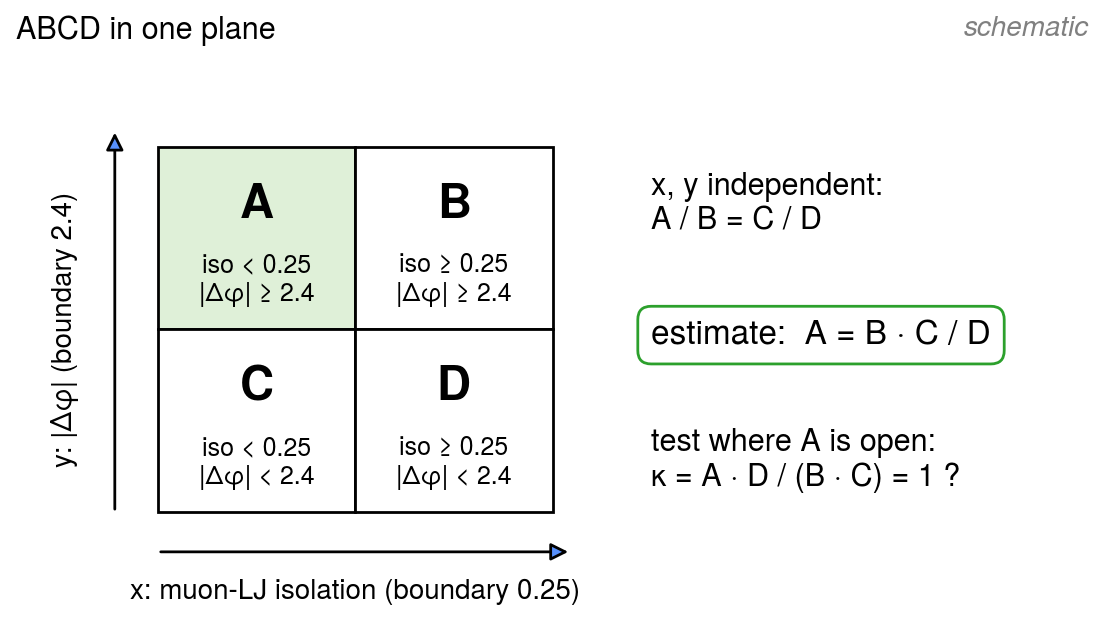

In [2]:
fig = npl.abcd_cartoon()
plt.show()

## 2. Our objects and variables

A **lepton jet (LJ)** is a cluster of collimated leptons and photons, the signature of a light
dark photon decaying to a lepton pair. A **muon LJ** is built from muons, an **egamma LJ** from
electrons and photons. A 2μ2e event has one of each.

The two ABCD variables are properties of the pair:

* **x = the muon LJ's isolation.** Take the nearest jet within ΔR < 0.4 of the muon LJ and remove
  from its energy all of its electromagnetic and muon energy (the jet's charged and neutral
  electromagnetic fractions and its muon fraction, whichever particles carry them, not only the
  LJ's own); the remainder divided by the LJ's energy is the isolation. It is 0 when no jet is near.
  The histograms clip negative values at zero: the jet's energy fractions can sum to slightly more
  than one, which makes an isolated LJ's value slightly negative. A signal LJ is isolated; a muon LJ
  inside a QCD jet is not.
* **y = |Δφ|, the azimuthal angle between the two LJs.** The two LJs of a signal event come from
  one heavy particle at rest and are back-to-back (|Δφ| near π). Most background pairs are
  back-to-back too: among the events that fail the isolation cut, the ratio of pairs with |Δφ| ≥ 2.4
  to the rest, B/D, is 2.7 in DD, 3.2 in PD and 4.1 in PP (the planes of section 3),
  against 0.31 for a flat |Δφ| distribution; the signal is more sharply peaked at π.

The background in B, C and D is a mix (Drell–Yan, photon conversions, jets misidentified as lepton
jets) whose composition the simulation cannot give at these counts: its effective event counts in
B, C and D of DD are 1.7, 3.1 and 7.2. Independence of x and y is therefore tested in data, not argued
from the physics of the background.

The search region's other cuts (the validation regions relax them as stated in sections 5 and 6): the egamma LJ is isolated (its isolation, defined the same way,
< 0.5); the LJ-pair mass M(LJ, LJ) ≥ 150 GeV; both LJs displaced (section 3).

The **working point** (WP) is the pair of cuts that defines A: isolated means isolation < 0.25,
back-to-back means |Δφ| ≥ 2.4. A **sideband** is a region next to A that fails one or both cuts:
here B (isolation ≥ 0.25), C (|Δφ| < 2.4) and D. The sidebands start right at A's edges, with no
**buffer band** between them. The earlier version of `estimate.ipynb` left a buffer (B at
isolation ≥ 0.5, C and D at |Δφ| < 2.0); the buffers were most of the non-closure it saw in the
prompt plane, and were removed (`estimate.ipynb`, section 4).

*How to read the figure:* the isolation × |Δφ| distribution of the plane with both LJs prompt
(PP, section 3) above 150 GeV; colour is events per cell on a log scale; the isolation and the |Δφ|
bins are both non-uniform and are drawn with equal width, with the stored edges as tick labels; the
red lines are the working point, and each region's total is written in it (797/1545/202/379 events in
A/B/C/D).

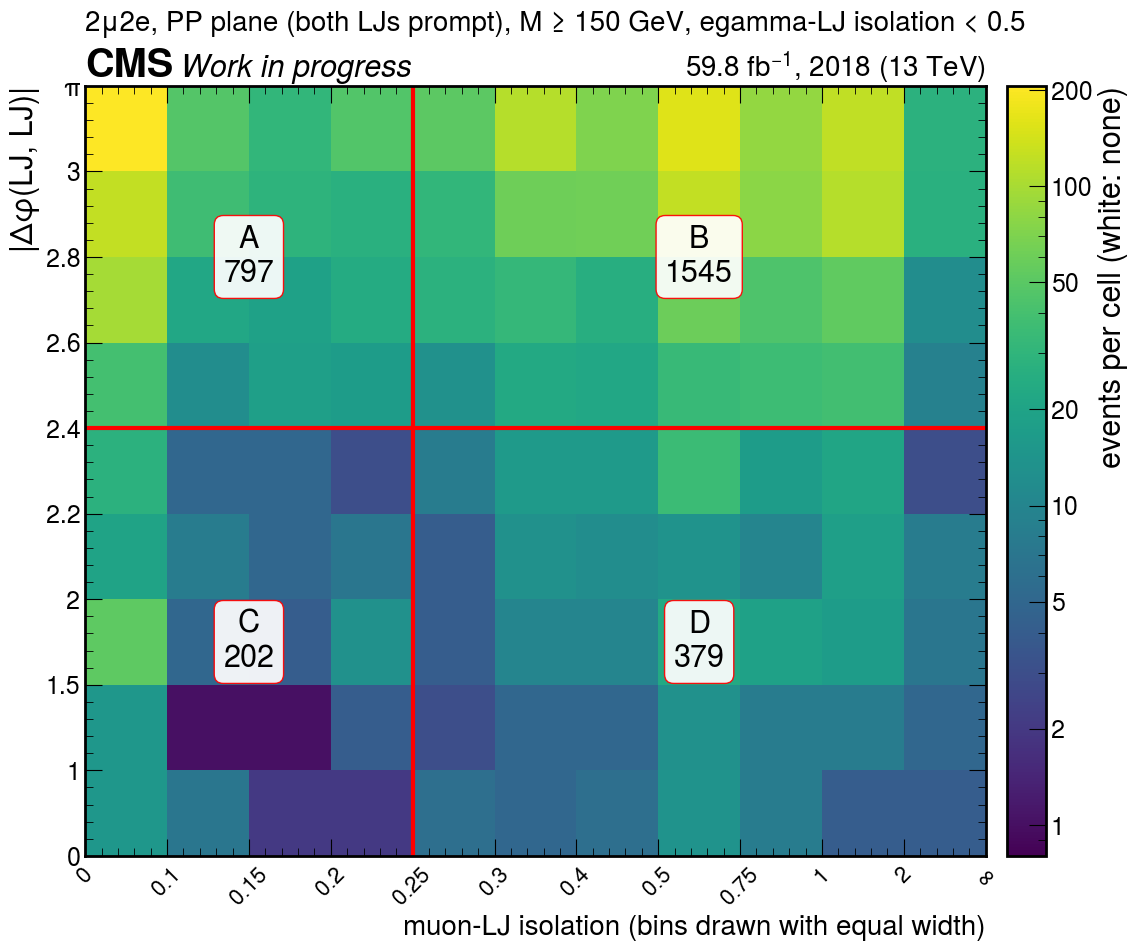

DD: B/D = 78/29 = 2.69
PD: B/D = 1401/433 = 3.24
PP: B/D = 1545/379 = 4.08


simulated background in B/C/D of DD at the stored cross sections, yield (effective event count): B 157.0 (1.7), C 19.2 (3.1), D 28.7 (7.2)


In [3]:
fig = npl.plane_figure(nl.plane_hist2d(d2, NOMINAL, "PP"), NOMINAL,
                       "2μ2e, PP plane (both LJs prompt), M ≥ 150 GeV, egamma-LJ isolation < 0.5", "nominal_plane_PP")
plt.show()
for p in ("DD", "PD", "PP"):
    reg = ps.regions(d2, NOMINAL, p)
    print(f"{p}: B/D = {reg['B'][0]:.0f}/{reg['D'][0]:.0f} = {reg['B'][0] / reg['D'][0]:.2f}")
BKG = tl.summed_cubes(BASE, "bkg", prefix="abcd8d")["2mu2e"]     # simulation, never hidden
print("simulated background in B/C/D of DD at the stored cross sections, yield (effective event count):",
      ", ".join(f"{r} {v[0]:.1f} ({tl.n_eff(v):.1f})" for r, v in ps.regions(BKG, NOMINAL, "DD").items() if r != "A"))
del BKG

## 3. The four planes and the hidden box

Each LJ is **prompt** or **displaced**, judged from hit counts in the tracker:

* a muon LJ is displaced when the largest number of **pixel hits** (hits in the innermost tracker
  layers) over its PF muons (the muons reconstructed with a tracker track) is ≤ 2, prompt when it
  is ≥ 3. A **DSA muon** (displaced standalone muon, reconstructed from the muon chambers alone)
  adds no pixel hits, so it never makes an LJ prompt: the LJ is displaced only when none of its PF
  muons has 3 or more pixel hits, and an LJ made only of DSA muons is displaced by that rule;
* an egamma LJ is displaced when the smallest number of **lostHits** (missing hits in the inner
  tracker before the first hit of an electron's track) over its electrons is ≥ 1, prompt when it is
  0. A photon-only egamma LJ has no track and counts as displaced.

That gives four planes, named by the muon LJ first: **PP**, **PD** (muon LJ prompt, egamma LJ
displaced), **DP** and **DD**. DD is the search plane. **Blinding** means that a region where the
signal is expected is not looked at until the method is fixed. The hidden box is region A of DD
above 150 GeV: muon-LJ isolation < 0.25, egamma-LJ isolation < 0.5, |Δφ| ≥ 2.4, M(LJ, LJ) ≥
150 GeV, both LJs displaced. Its B, C and D are
open, and so is everything below 150 GeV and every other plane.

*How to read the figure:* the four planes as a 2 × 2 grid (rows: muon LJ prompt, displaced;
columns: egamma LJ prompt, displaced), each split into A (top left), B, C and D with the data
counts above 150 GeV; the hatched cell is the hidden box.

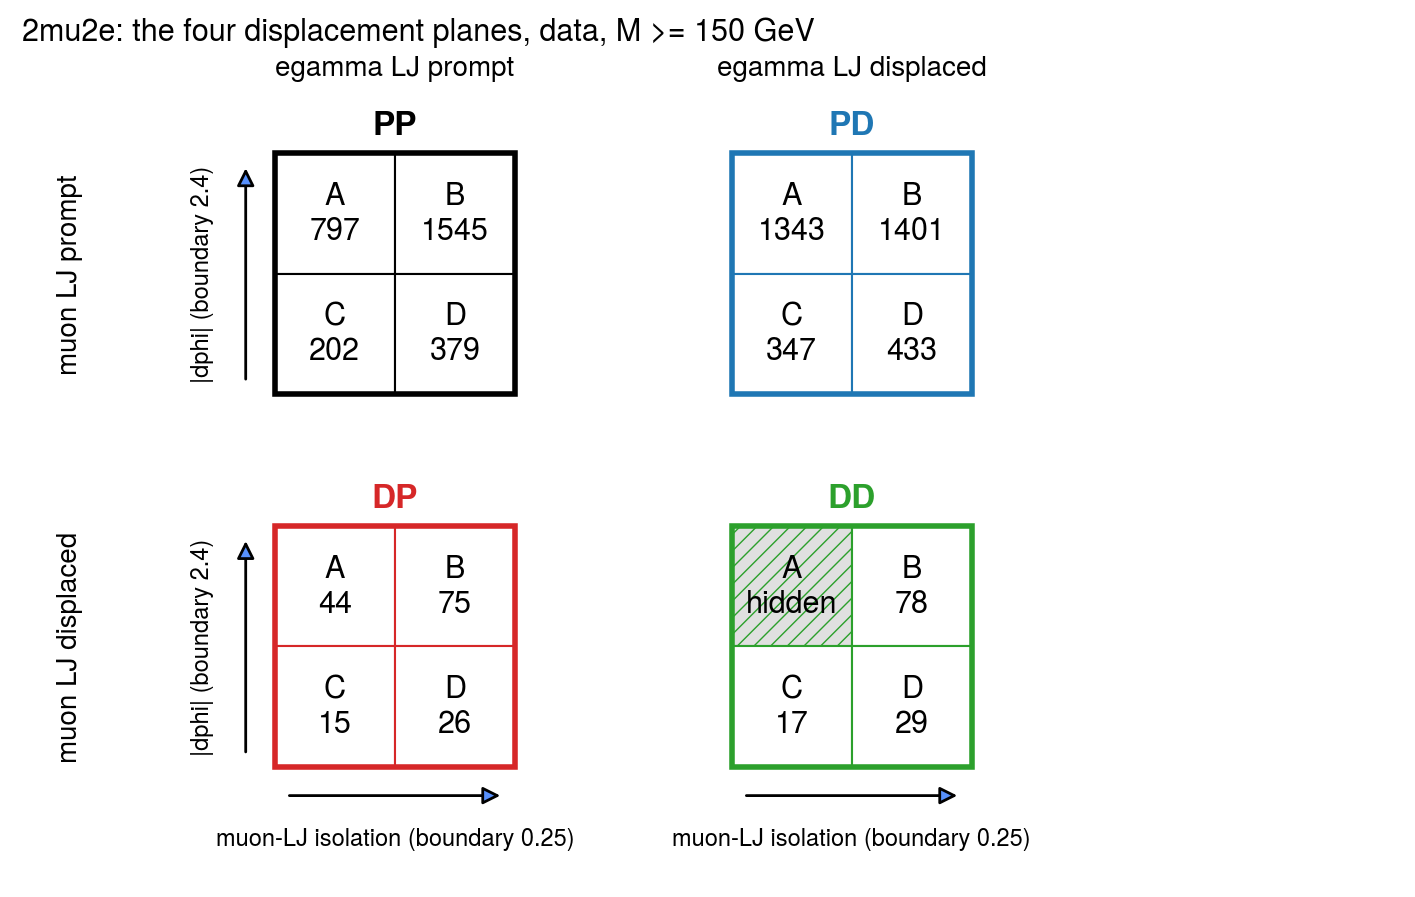

In [4]:
fig = bp.planes_cartoon(d2, NOMINAL, "2mu2e", routes=False)
plt.show()

## 4. The estimate

In DD above 150 GeV, B, C and D hold 78, 17 and 29 events, and

**A = B·C/D = 45.7 ± 14.9 events** (statistical error 33%, from the Poisson errors of the three
counts propagated through the product to first order, as `estimate_lib` and `plane_search_lib` do
it). A Poisson bootstrap of B, C and D (each count redrawn 40000 times from a Poisson
distribution whose mean is the observed count) gives the asymmetric 68% interval 32–63 (−14/+17);
the headline keeps the symmetric ± 15 of first-order propagation.

The table gives the counts and the prediction; κ cannot be computed because A is hidden. In its
definition column, "D / D" gives the displacement of the muon LJ and of the egamma LJ (P prompt, D
displaced, "any" either), followed by the egamma-LJ isolation band and the mass window. This
number assumes κ = 1 in the search plane above 150 GeV. The rest of the notebook is about how well
that is justified and what uncertainty to assign to it.

*How to read the figure:* as in section 2, for the search plane; the hatched cells are the hidden
box and region A reads "hidden".

,region,definition,A,B,C,D,B C/D,kappa,precision
0,search region,"D / D, egamma iso < 0.5, M ≥ 150 GeV",hidden,78,17,29,45.7 ± 14.9,hidden (A in the box),n/a


Poisson bootstrap of B, C, D (40000 toys): 16th/50th/84th percentiles 32.2/45.2/62.6


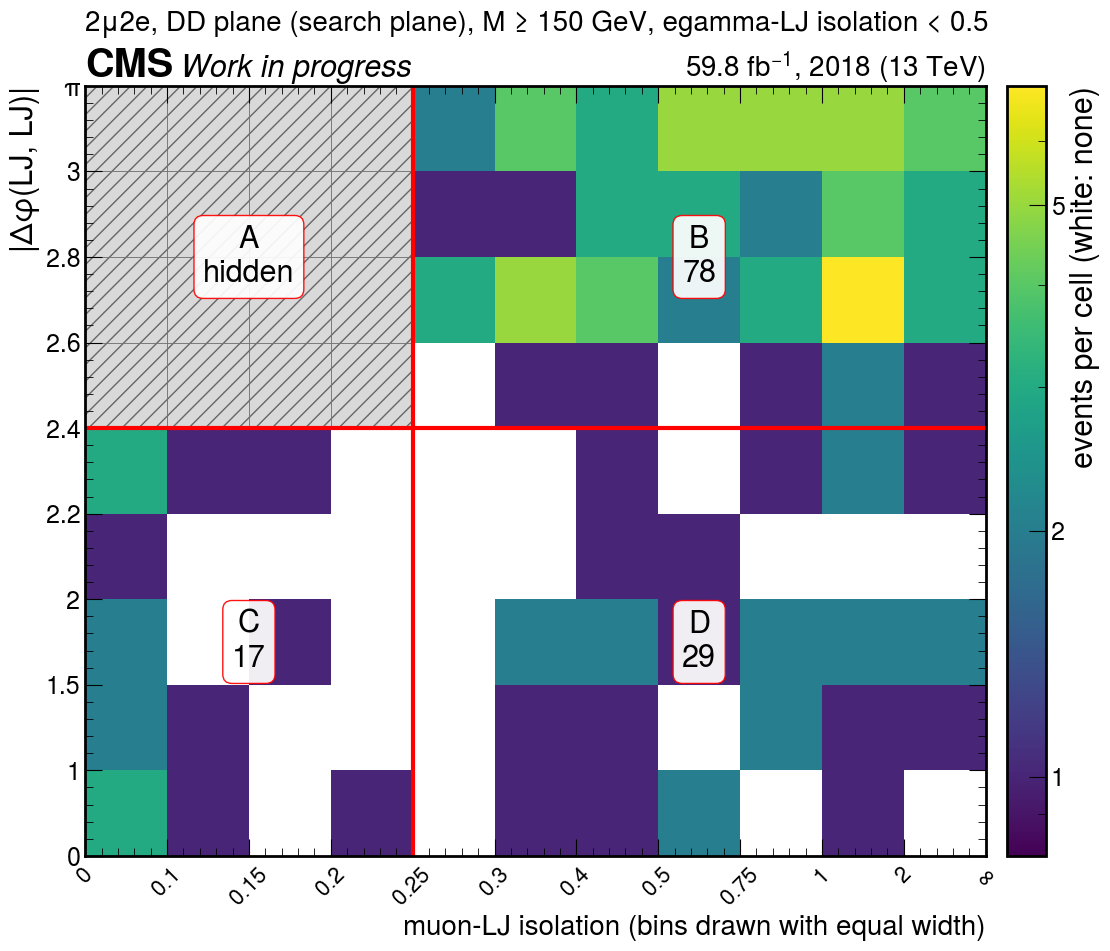

In [5]:
display(nl.kappa_view(nl.kappa_table(d2, [nl.SR], NOMINAL)))
EST = nl.kappa_row(d2, nl.SR, NOMINAL)
HB = nl.interval68(nl.bootstrap_abcd([(EST["B"], EST["C"], EST["D"])])["one_bin"])
print(f"Poisson bootstrap of B, C, D ({nl.BOOTSTRAP_TOYS} toys): 16th/50th/84th percentiles {HB[0]:.1f}/{HB[1]:.1f}/{HB[2]:.1f}")
fig = npl.plane_figure(nl.plane_hist2d(d2, NOMINAL, "DD"), NOMINAL,
                       "2μ2e, DD plane (search plane), M ≥ 150 GeV, egamma-LJ isolation < 0.5", "nominal_plane_DD")
plt.show()

## 5. Validation 1: κ wherever A is open

A **validation region** is a region like the search region whose A can be looked at. Four come
for free: the planes PP, PD and DP above 150 GeV, and the search plane itself below 150 GeV.
Four more are the search plane above 150 GeV with the egamma LJ not isolated, in the bands of
egamma-LJ isolation ≥ 0.5, ≥ 0.75, ≥ 1 and 0.5–1 (the hidden box ends at 0.5): they are the only open regions with
both LJs displaced in the search mass window, and they differ from the search region only in the
egamma LJ's isolation. The table gives A, B, C, D, the prediction B·C/D and κ with its 68%
interval. That interval combines the Clopper–Pearson intervals of the two ratios A/C and B/D (each
the interval of the fraction A/(A+C), or B/(B+D), mapped to the ratio): their relative errors are
added in quadrature, the lower side of A/C with the upper side of B/D and the other way round. The
error of B·C/D is first-order propagation of the three Poisson errors. "Precision" is the larger
side of κ's interval over κ.

* PP closes: κ = 0.97 ± 0.10 (797/1545/202/379).
* PD is 20% above one, 2.0 standard deviations: κ = 1.20 ± 0.10 (1343/1401/347/433).
* DP, κ = 1.02 -0.41 +0.48 (44/75/15/26), and DD below 150 GeV, κ = 1.26 ± 0.44 (41/32/53/52), are consistent with
  one but imprecise: their errors are 35%–47% of the value, so they cannot tell 1.0 from 1.3.
* The search plane above 150 GeV with the egamma LJ not isolated, egamma-LJ isolation ≥ 0.5: κ = 0.67 ± 0.60 (20/30/6/6); egamma-LJ isolation ≥ 0.75: κ = 2.75 -2.75 +14.54 (11/20/1/5); egamma-LJ isolation ≥ 1: κ undefined (5/16/0/2; C empty); egamma-LJ isolation 0.5–1: κ = 0.71 ± 0.71 (15/14/6/4). Their errors are
  89%–529% of the value: none of them is measured to 20% or better, so none can carry the systematic of section 8.

*How to read the figure:* κ per region with its 68% interval; the dashed line is κ = 1; a value
above the drawn range is marked by an arrow at the top edge, with its value written beside the error bar, and an undefined κ (an empty
region) is marked as such.

,region,definition,A,B,C,D,B C/D,kappa,precision
0,PP,"P / P, egamma iso < 0.5, M ≥ 150 GeV",797,1545,202,379,823.5 ± 74.7,0.97 ± 0.10,10%
1,PD,"P / D, egamma iso < 0.5, M ≥ 150 GeV",1343,1401,347,433,1122.7 ± 86.3,1.20 ± 0.10,8%
2,DP,"D / P, egamma iso < 0.5, M ≥ 150 GeV",44,75,15,26,43.3 ± 14.9,1.02 -0.41 +0.48,47%
3,DD < 150,"D / D, egamma iso < 0.5, M < 150 GeV",41,32,53,52,32.6 ± 8.6,1.26 ± 0.44,35%
4,"DD, egamma iso ≥ 0.5","D / D, egamma iso ≥ 0.5, M ≥ 150 GeV",20,30,6,6,30.0 ± 18.2,0.67 ± 0.60,89%
5,"DD, egamma iso ≥ 0.75","D / D, egamma iso ≥ 0.75, M ≥ 150 GeV",11,20,1,5,4.0 ± 4.5,2.75 -2.75 +14.54,529%
6,"DD, egamma iso ≥ 1","D / D, egamma iso ≥ 1, M ≥ 150 GeV",5,16,0,2,n/a,n/a,n/a
7,"DD, egamma iso 0.5–1","D / D, egamma iso 0.5–1, M ≥ 150 GeV",15,14,6,4,21.0 ± 14.7,0.71 ± 0.71,100%


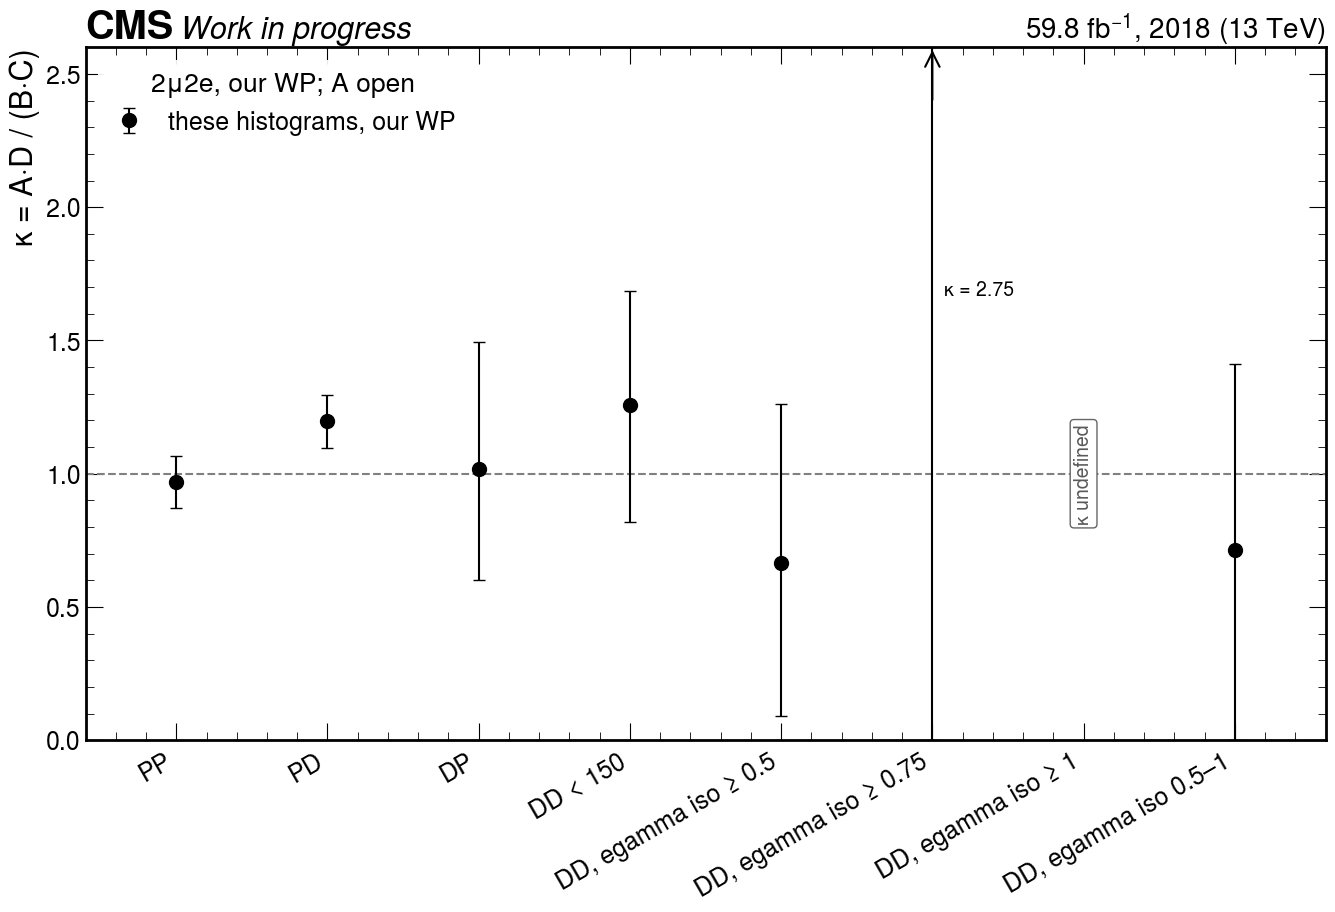

In [6]:
VAL1 = nl.kappa_table(d2, [VRS[n] for n in ("PP", "PD", "DP", "DD < 150")] + list(nl.dd_band_vrs()), NOMINAL)
display(nl.kappa_view(VAL1))
fig = npl.kappa_points_figure(*npl.table_points(VAL1), "2μ2e, our WP; A open", "nominal_kappa_open", ylim=(0, 2.6), width=16)
plt.show()

## 6. Validation 2: the seven validation regions of Dongyub Lee's programme

Dongyub Lee tested the same plane (muon-LJ isolation × |Δφ|) in seven data validation regions
(slides of 2026-10-13 and 2026-10-16), with his own analysis code reading his 6D histograms: the
group's earlier histograms of the data in six variables (the isolation and the displacement
variable of each LJ, |Δφ| and the LJ-pair mass), filled by his campaigns. This notebook's 8D
histograms add the mass of the muon LJ and its number of DSA muons. His histograms carry the data
of the search region unblinded: no blinding cut is applied in his campaigns. The table defines the regions: the
displacement of each LJ (P prompt, D displaced, "any" = either), the egamma-LJ isolation band and
the mass window. His working point is isolation < 0.3 and |Δφ| ≥ 2.6 (ours: < 0.25 and ≥ 2.4);
V1 keeps the egamma LJ isolated (< 0.5); V2–V4 put it in a non-isolated band (≥ 1 or ≥ 0.75),
which keeps their A away from the signal; V5–V7 use bands, 0.2–1 and 0.15–1, that straddle the
isolation boundary 0.5 of the search region, so they hold isolated and non-isolated egamma LJs
alike (V7 overlaps V1 in 0.15–0.5). At our working point V1 selects exactly the events of PP (797/1545/202/379 in A/B/C/D), so the two are one validation region, not two.

His regions test the method on populations with a prompt muon LJ: V1, V2, V5, V6 and V7 require one; V3 and V4 admit either state of the muon LJ but lie below 150 GeV.
None has a displaced muon LJ above 150 GeV, the population of the search region. The displacement that defines the search
region is tested by PD on the egamma side, imprecisely by DP and by DD below 150 GeV, and by the DD
bands of section 5. We recompute all seven from our histograms at his working point and at ours.

* **At his working point** the slides read 1.03/1.01/1.02/1.01/1.07/1.05/1.05, these histograms 1.03/1.01/1.02/1.01/1.07/1.05/1.06 (errors
  0.06–0.09): equal to the printed digit in 6 of 7 regions; V7 reads 1.057 here against 1.05 on the slides and so rounds differently. The A counts agree
  within 0.0%–0.6%. This is two codes on one data set: a cross-check of both codes,
  not an independent measurement. The A counts differ by selection details we cannot remove (our
  HEM15/16 veto applies to runs ≥ 319077 only, his to every run; our raw-event pre-filter; our
  isolation clipped at zero).
* **At our working point** the same regions read 0.97/0.87/0.88/0.93/1.05/1.03/1.03. In the three low-mass regions V2–V4,
  κ falls from 1.01–1.02 at his working point to 0.87–0.93 at ours, by 0.08–0.14. The
  two working points share most events, so the error of the shift is not that of either κ
  (0.07–0.09): the edges 0.25 and 0.3 in the isolation and 2.4 and 2.6 in |Δφ| cut the plane into 9 disjoint blocks with
  independent Poisson counts, and propagating them to first order into the difference of the two κ
  gives 0.05–0.06. The shift is 1.7–2.4 standard deviations in V2–V4, and 0.3–0.9
  in the four regions above 150 GeV, which read 0.97–1.05 at ours. κ depends on the working
  point in the low-mass regions. No working-point systematic is assigned: the group sets the working
  point, κ and "closes" are statements at a working point, and the rule of section 8 is applied at
  ours.
* None of the seven touches the hidden box. His working point applied to the search plane puts
  A and C of DD inside the box (C then reaches into 2.4 ≤ |Δφ| < 2.6 at isolation
  < 0.25): there is no DD estimate at his working point, as the second table shows.

*How to read the figure:* κ per region from the slides (grey squares), from these histograms at
his working point (orange diamonds) and at ours (black circles); the dashed line is κ = 1.

,region,"definition (muon LJ / egamma LJ, egamma iso, M)","kappa, slides","kappa, these histograms at his WP","kappa, these histograms at our WP",A slides / ours (his WP),A ours (our WP)
0,V1,"P / P, egamma iso < 0.5, M ≥ 150 GeV",1.03 ± 0.09,1.03 ± 0.09,0.97 ± 0.10,819 / 821,797
1,V2,"P / any, egamma iso ≥ 1, M < 150 GeV",1.01 ± 0.09,1.01 ± 0.09,0.87 ± 0.09,565 / 566,529
2,V3,"any / P, egamma iso ≥ 0.75, M < 150 GeV",1.02 ± 0.08,1.02 ± 0.09,0.88 ± 0.08,622 / 622,576
3,V4,"any / any, egamma iso ≥ 0.75, M < 150 GeV",1.01 ± 0.07,1.01 ± 0.07,0.93 ± 0.07,860 / 862,822
4,V5,"P / any, egamma iso 0.2–1, M ≥ 150 GeV",1.07 ± 0.07,1.07 ± 0.07,1.05 ± 0.08,1680 / 1685,1651
5,V6,"P / any, egamma iso 0.15–1, M ≥ 150 GeV",1.05 ± 0.06,1.05 ± 0.06,1.03 ± 0.07,1870 / 1878,1843
6,V7,"P / P, egamma iso 0.15–1, M ≥ 150 GeV",1.05 ± 0.08,1.06 ± 0.09,1.03 ± 0.10,1020 / 1026,990


the search region at both working points


,region,"definition (muon LJ / egamma LJ, egamma iso, M)","kappa, slides","kappa, these histograms at his WP","kappa, these histograms at our WP",A slides / ours (his WP),A ours (our WP)
0,search region,"D / D, egamma iso < 0.5, M ≥ 150 GeV",,hidden (A and C in the box),hidden (A in the box),hidden,hidden


the shift of kappa from his working point to ours, with the error of the difference (shared events counted once)


,region,kappa at his WP,kappa at our WP,shift,error of the shift,shift / error
0,V1,1.031,0.968,-0.063,0.069,-0.921
1,V2,1.010,0.875,-0.136,0.058,-2.337
2,V3,1.016,0.884,-0.132,0.054,-2.438
3,V4,1.008,0.928,-0.080,0.047,-1.697
4,V5,1.070,1.050,-0.020,0.055,-0.357
5,V6,1.046,1.029,-0.016,0.050,-0.324
6,V7,1.057,1.034,-0.023,0.070,-0.335


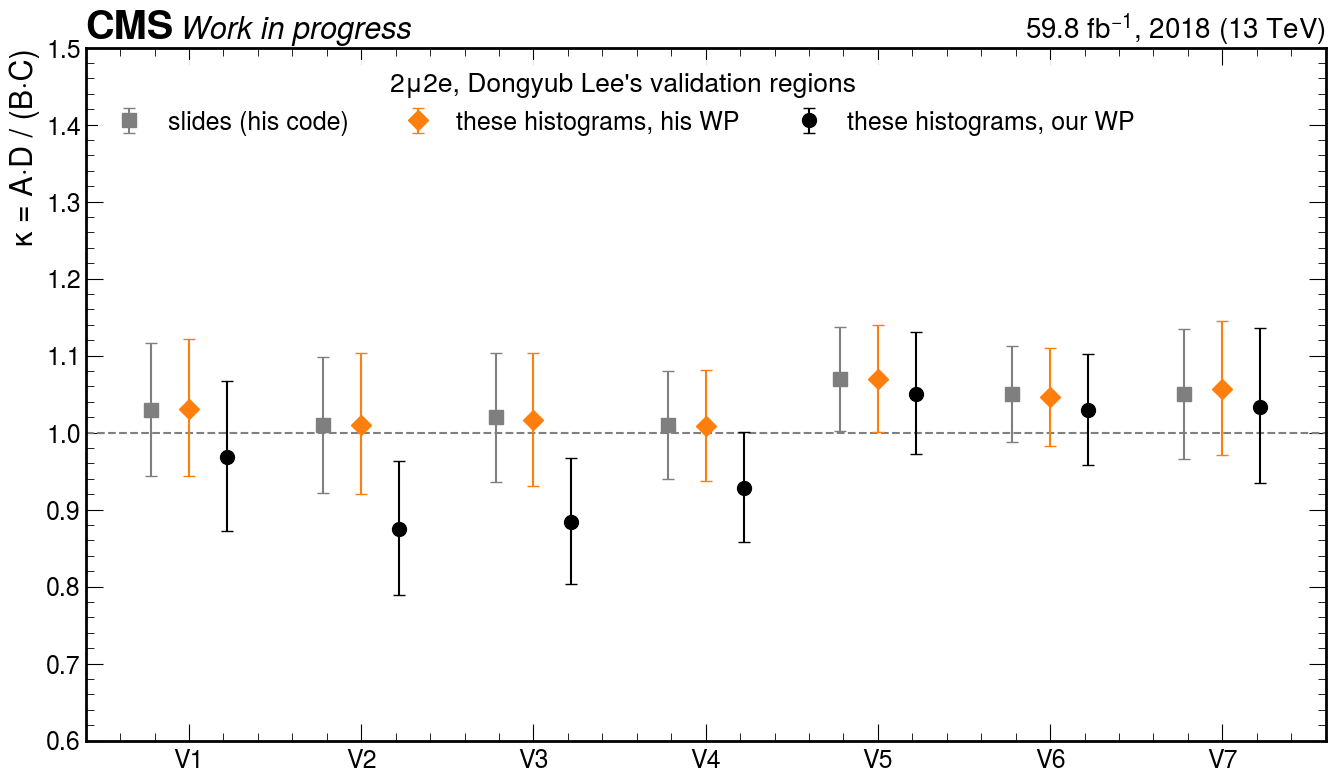

In [7]:
VRT = nl.vr_table(d2, nl.DONGYUB_VRS)
display(nl.vr_comparison_view(VRT))
print("the search region at both working points")
display(nl.vr_comparison_view(nl.vr_table(d2, (nl.SR,))))
print("the shift of kappa from his working point to ours, with the error of the difference (shared events counted once)")
display(nl.wp_shift_table(d2, nl.DONGYUB_VRS).round(3))
fig = npl.kappa_points_figure(*npl.vr_points(VRT), "2μ2e, Dongyub Lee's validation regions", "nominal_kappa_dongyub",
                              ylim=(0.6, 1.5))
plt.show()

## 7. Validation 3: does κ depend on what differs between the validation regions and the search region?

The search region differs from every validation region in at least one respect. If κ depends on
one of them, the validation regions can mislead. Six checks.

### 7a. The displacement ladder

From PP (no displaced LJ) through PD and DP (one) to DD below 150 GeV and the DD bands above
150 GeV (two): κ = 0.97 ± 0.10, 1.20 ± 0.10, 1.02 -0.41 +0.48, 1.26 ± 0.44, and, in the bands, 0.67, 2.75, undefined and 0.71 for egamma-LJ isolation ≥ 0.5, ≥ 0.75, ≥ 1 and 0.5–1. Nothing
trends with the number of displaced LJs beyond the errors; the two-displaced points carry errors of
35% and more.

*How to read the figure:* κ against the number of displaced LJs in the plane, each point labelled
with its region; the dashed line is κ = 1; a value above the drawn range is marked by an arrow at the top edge, with its value written beside the error bar; an undefined κ is marked as such.

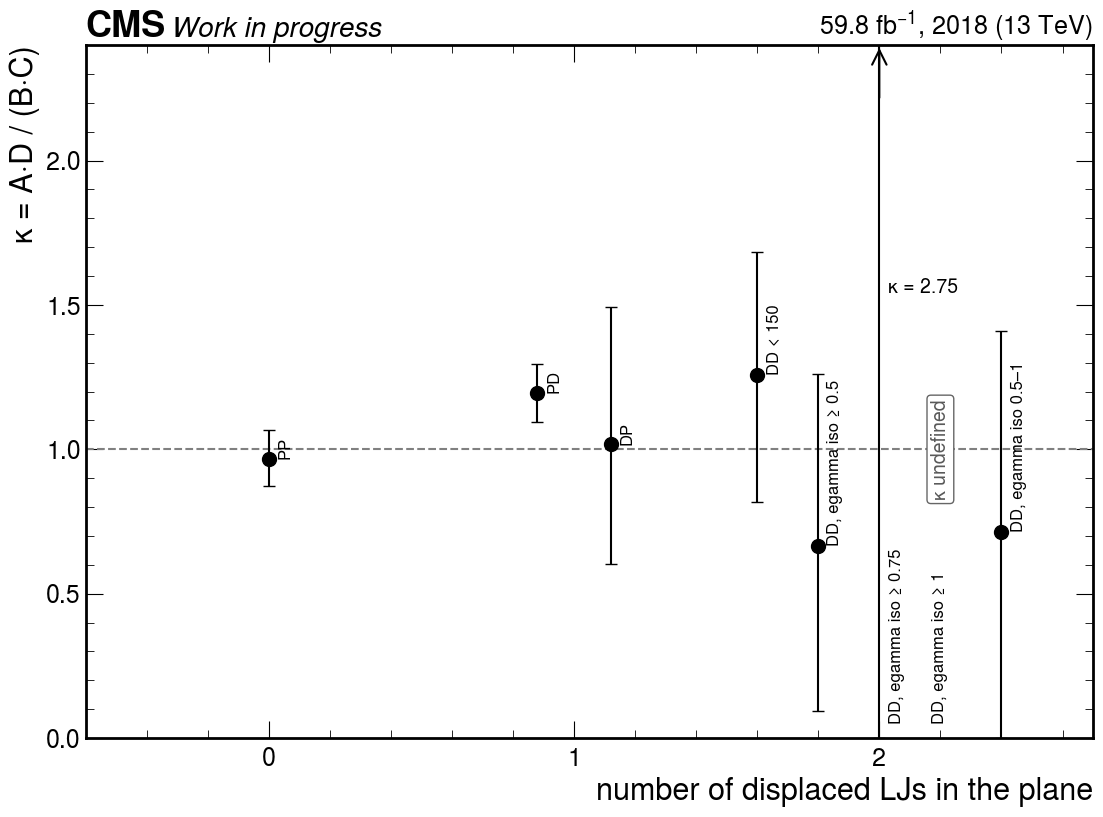

In [8]:
fig = npl.ladder_figure([(r["region"], (VRS[r["region"]].mu == "D") + (VRS[r["region"]].egm == "D"),
                          (r["kappa"], r["minus"], r["plus"])) for _, r in VAL1.iterrows()])
plt.show()

### 7b. The egamma LJ type

Here **PD:g** denotes the events of PD whose egamma LJ is photon-only (it contains no electron,
so no track), and **PD:e** those whose egamma LJ contains at least one electron, with or without
photons: an LJ with one electron and some photons is "e", its lost hits being the electron's.
PD's deviation sits in its photon-only egamma LJs: κ = 1.27 ± 0.12 for them, 0.77 ± 0.20 for the electron
ones, which make up 10% of PD's A. Photon-only egamma LJs count as displaced (no track, section 3), so no prompt plane contains
them; they enter PD and DD only. The photon-only share per region is 90%/86%/87%/88% in A/B/C/D of PD and
88%/94%/83% in B/C/D of DD: summed over B, C and D, DD's sidebands (88% photon-only) are
as photon-rich as PD's (86%). If κ follows the photon-only share, κ of DD is more likely to sit near
PD's 1.20 ± 0.10 than near PP's 0.97 ± 0.10. That is the case the systematic of section 8 has to cover.

*How to read the figure:* the photon-only share of the egamma LJs in each region of PD (blue) and
DD (green), with binomial errors and the number of events in brackets; A of DD is hidden.

,plane,A,B,C,D,A/B,B/D,C/D,kappa
0,PD,1343,1401,347,433,0.96 ± 0.04,3.24 -0.18 +0.19,0.80 -0.06 +0.06,1.20 ± 0.10
1,PD:g,1207,1201,301,381,1.00 ± 0.04,3.15 -0.19 +0.20,0.79 -0.06 +0.07,1.27 ± 0.12
2,PD:e,136,200,46,52,0.68 -0.08 +0.08,3.85 -0.59 +0.70,0.88 -0.18 +0.22,0.77 ± 0.20


,plane,region,events,e,g
0,PD,A,1343,136 (10%),1207 (90%)
1,PD,B,1401,200 (14%),1201 (86%)
2,PD,C,347,46 (13%),301 (87%)
3,PD,D,433,52 (12%),381 (88%)
4,DD,A,hidden,hidden,hidden
5,DD,B,78,9 (12%),69 (88%)
6,DD,C,17,1 (6%),16 (94%)
7,DD,D,29,5 (17%),24 (83%)


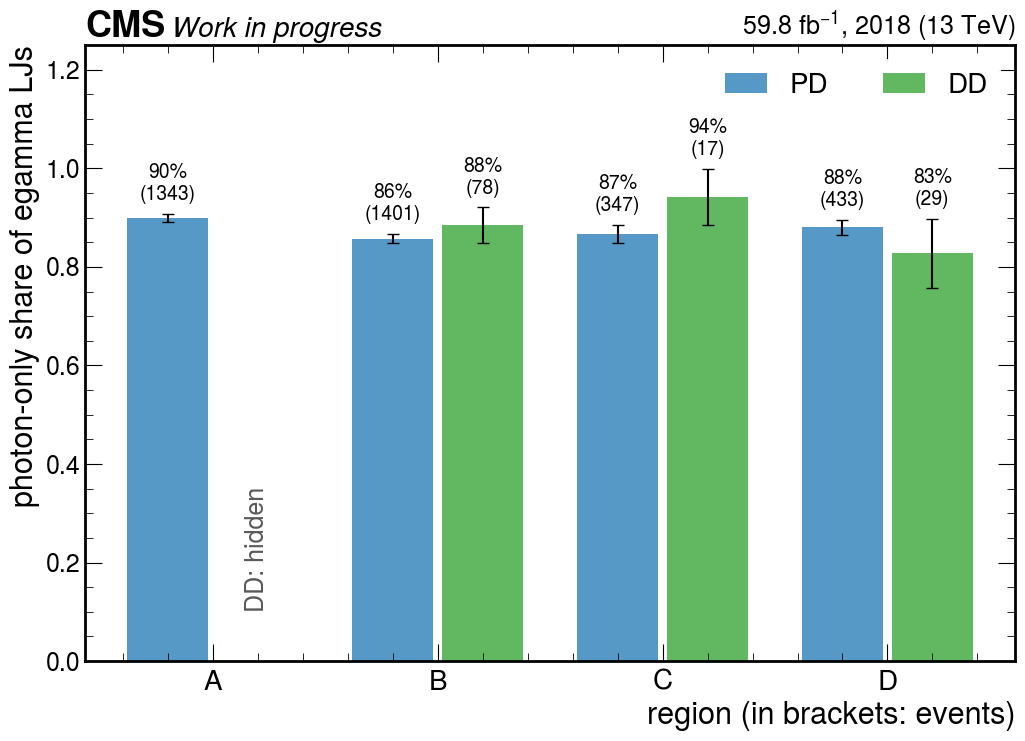

In [9]:
display(el.class_grid_table(d2, NOMINAL, ("PD",), (None, "g", "e")).drop(columns=["b-tag", "N_eff A"]))
SHARES_G = nl.class_share_table(d2, NOMINAL, ("PD", "DD"), ("e", "g"))
display(nl.class_share_view(SHARES_G, ("e", "g")))
fig = npl.photon_share_figure(SHARES_G)
plt.show()

### 7c. The muon LJ's DSA class

A muon LJ with a DSA muon (class `dsa1+`) is a different object from one without (`dsa0`). κ per
class: PP 1.02 ± 0.11 (`dsa0`) and 0.59 -0.18 +0.20 (`dsa1+`), PD 1.24 ± 0.11 and 0.73 -0.17 +0.19. The
`dsa1+` share of B/C/D is 14%/13%/17% in PD and 44%/29%/45% in DD. The two classes' κ differ by
1.9 standard deviations in PP and 2.3 in PD. In both planes κ of the `dsa1+` class is the lower one. DD's sidebands hold
2.2–3.1 times PD's `dsa1+` share, so if the class difference carries over to DD it pulls κ of DD
down, from 1.20 to about 1.11 (section 8), against the photon argument of 7b, which pulls it up. The direct estimate uses DD's own sidebands and needs no class weighting; the class
matters for any argument that borrows κ, or a ratio, from PD.

In [10]:
display(el.class_grid_table(d2, NOMINAL, ("PP", "PD"), (None, "dsa0", "dsa1+")).drop(columns=["b-tag", "N_eff A"]))
display(nl.class_share_view(nl.class_share_table(d2, NOMINAL, ("PD", "DD"), ("dsa0", "dsa1+")), ("dsa0", "dsa1+")))

,plane,A,B,C,D,A/B,B/D,C/D,kappa
0,PP,797,1545,202,379,0.52 ± 0.02,4.08 -0.23 +0.25,0.53 -0.05 +0.05,0.97 ± 0.10
1,PP:dsa0,740,1370,176,332,0.54 ± 0.03,4.13 -0.25 +0.27,0.53 -0.05 +0.05,1.02 ± 0.11
2,PP:dsa1+,57,175,26,47,0.33 -0.05 +0.06,3.72 -0.60 +0.73,0.55 -0.13 +0.17,0.59 -0.18 +0.20
3,PD,1343,1401,347,433,0.96 ± 0.04,3.24 -0.18 +0.19,0.80 -0.06 +0.06,1.20 ± 0.10
4,PD:dsa0,1253,1203,301,359,1.04 ± 0.04,3.35 -0.20 +0.21,0.84 -0.07 +0.07,1.24 ± 0.11
5,PD:dsa1+,90,198,46,74,0.45 -0.06 +0.07,2.68 -0.36 +0.42,0.62 -0.12 +0.14,0.73 -0.17 +0.19


,plane,region,events,dsa0,dsa1+
0,PD,A,1343,1253 (93%),90 (7%)
1,PD,B,1401,1203 (86%),198 (14%)
2,PD,C,347,301 (87%),46 (13%)
3,PD,D,433,359 (83%),74 (17%)
4,DD,A,hidden,hidden,hidden
5,DD,B,78,44 (56%),34 (44%)
6,DD,C,17,12 (71%),5 (29%)
7,DD,D,29,16 (55%),13 (45%)


### 7d. The mass

κ in 150–300 GeV and above 300 GeV: PP 1.08 ± 0.13 → 0.67 -0.15 +0.15, PD 1.31 ± 0.12 → 0.87 ± 0.17. κ falls
with the mass in both planes; the drop, combined over the two planes, is 0.42 ± 0.14 (2.9 standard
deviations). That is a test with one degree of freedom of a split at 300 GeV chosen after looking
at the bins. The table under the figure also gives the χ² of the five mass bins against a constant
κ equal to the integrated value, an omnibus test that spreads a monotone trend over four degrees of
freedom and so dilutes it: 3.9/4 in PP (p = 0.42) and 3.9/4 in PD (p = 0.42).
Both are shown.

For a one-bin search region the integrated κ of section 5 is the right test if the validation
plane's mass distribution resembles the search plane's, so that the mass dependence averages the
same way in both. In D it roughly does: 90% of DD's D lies in 150–300 GeV, against
82% of PD's.

The same question asked of the estimate itself. The direct estimate above 300 GeV alone is
52.0 events from B/C/D = 26/6/3, with a 68% interval of 24–110 from a Poisson bootstrap of
the three counts (40000 toys, those with D = 0 dropped); in 150–300 GeV it is 22.0, and the
sum of the two windows, 74 events, has the interval 46–134. The ratio of that sum to the
one-bin estimate, Σ_w B_w C_w/D_w ÷ (B·C/D), is 1.03 in PP, 1.01 in PD and 1.62
in DD; for DD its bootstrap 16th/50th/84th percentiles are 1.15/1.59/2.70, and it is below one in
3% of the toys. The ratio has a direct meaning: the one-bin κ equals Σ_w A_w ÷ (B·C/D),
so if the two variables are independent within each window, the one-bin estimate is low by exactly
that ratio. The mass window acts as a third variable that correlates with both ABCD variables in
DD: above 300 GeV lie 33%/35%/10% of DD's B/C/D, so C/D is 0.42 and 2.00 in the two windows. It does
not in PP or PD (29%/23%/19% and 25%/20%/18% of B/C/D above 300 GeV, C/D 0.50 and 0.65 and
0.78 and 0.90), where the ratio is 1.01–1.03; the open planes therefore cannot test it, and in DD
it rests on 3 events in D above 300 GeV. This is a caveat on the one-bin estimate that the
systematic rule of section 8 does not cover; a search region binned in mass, or more data, resolves
it. For a search region binned in mass, each bin needs its own κ, and the per-window deviations of
PP and PD, up to 33%, would be the systematic. This notebook estimates the one-bin search
region.

*How to read the figure:* κ per mass window in PP (black) and PD (blue); the dashed line is κ = 1.
The table below it gives κ in the finer bins of the histograms.

,region,definition,A,B,C,D,B C/D,kappa,precision
0,"PP, 150–300","P / P, egamma iso < 0.5, M 150–300 GeV",598,1093,155,307,551.8 ± 56.9,1.08 ± 0.13,12%
1,"PP, ≥ 300","P / P, egamma iso < 0.5, M ≥ 300 GeV",199,452,47,72,295.1 ± 57.0,0.67 -0.15 +0.15,23%
2,"PD, 150–300","P / D, egamma iso < 0.5, M 150–300 GeV",1068,1049,276,354,817.9 ± 70.4,1.31 ± 0.12,9%
3,"PD, ≥ 300","P / D, egamma iso < 0.5, M ≥ 300 GeV",275,352,71,79,316.4 ± 54.4,0.87 ± 0.17,20%


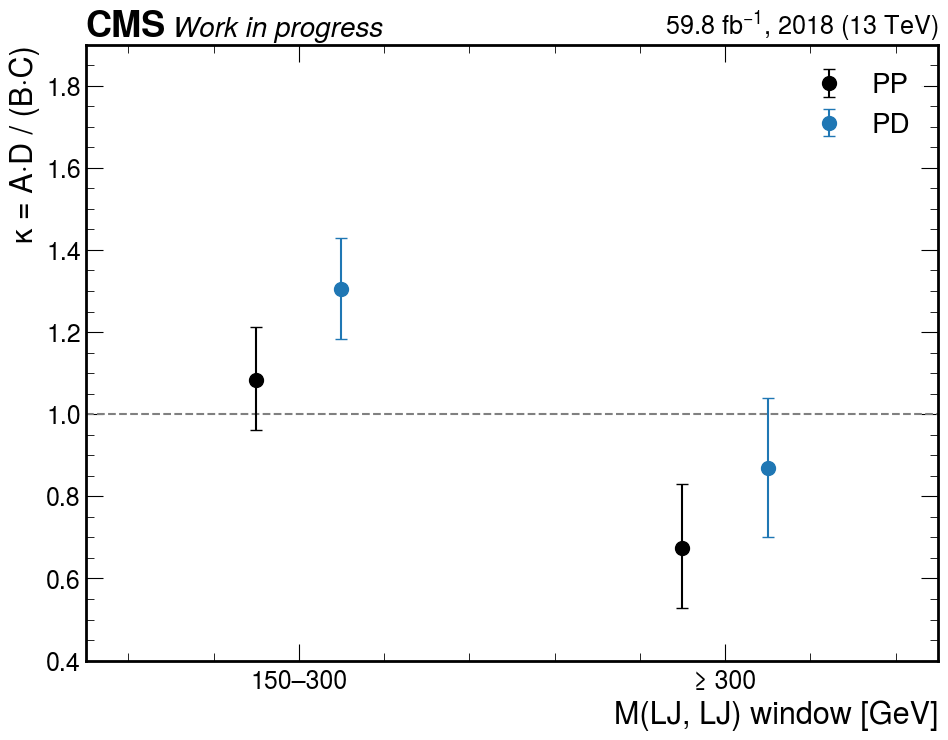

,plane,bin,A,B,C,D,kappa,A/B
0,PP,150-200,292,518,82,171,1.18 -0.18 +0.20,0.56 -0.04 +0.04
1,PP,200-300,306,575,73,136,0.99 -0.17 +0.18,0.53 -0.04 +0.04
2,PP,300-400,121,272,29,44,0.67 -0.19 +0.20,0.44 -0.05 +0.05
3,PP,400-600,52,133,15,24,0.63 -0.25 +0.29,0.39 -0.06 +0.08
4,PP,>=600,26,47,3,4,0.74 -0.74 +1.02,0.55 -0.13 +0.17
5,PP,all,,,,,0.97 ± 0.10,chi2 of the bins 3.9 / 4
6,PD,150-200,574,530,171,199,1.26 ± 0.16,1.08 -0.07 +0.07
7,PD,200-300,494,519,105,155,1.41 ± 0.21,0.95 -0.06 +0.06
8,PD,300-400,171,211,43,42,0.79 ± 0.21,0.81 -0.08 +0.09
9,PD,400-600,79,120,19,33,1.14 -0.40 +0.44,0.66 -0.09 +0.11


PP: chi2 of the five bins against the integrated kappa 3.9/4, p = 0.42
PD: chi2 of the five bins against the integrated kappa 3.9/4, p = 0.42
the direct estimate per mass window, summed, against the one-bin estimate


,plane,"B/C/D, 150-300","B/C/D, >= 300",B C/D summed over the windows,"B C/D, one bin",ratio
0,PP,1093/155/307,452/47/72,846.9,823.5,1.03
1,PD,1049/276/354,352/71/79,1134.2,1122.7,1.01
2,DD,52/11/26,26/6/3,74.0,45.7,1.62


DD, Poisson bootstrap (40000 toys; D > 0 in both windows in 95%), 16th/50th/84th percentiles:
  B C/D above 300 GeV: 24.0/50.0/110.0
  B C/D summed over the two windows: 45.8/74.4/134.2
  ratio of the sum to the one-bin estimate: 1.15/1.59/2.70 ; below one in 3% of the toys


In [11]:
MASS = nl.kappa_table(d2, [nl.VR(f"{p}, {w}", "this analysis", p[0], p[1], mass=m)
                           for p in ("PP", "PD") for w, m in (("150–300", (150.0, 300.0)), ("≥ 300", (300.0, None)))], NOMINAL)
display(nl.kappa_view(MASS))
fig = npl.kappa_mass_figure({p: [(r["kappa"], r["minus"], r["plus"]) for _, r in MASS[MASS["region"].str.startswith(p)].iterrows()]
                             for p in ("PP", "PD")}, ["150–300", "≥ 300"])
plt.show()
display(ps.mass_table(d2, NOMINAL, planes=("PP", "PD")))
for p in ("PP", "PD"):
    _, _, chi2, ndf = ps.kappa_vs_mass(d2, NOMINAL, p)
    print(f"{p}: chi2 of the five bins against the integrated kappa {chi2:.1f}/{ndf}, p = {stats.chi2.sf(chi2, ndf):.2f}")
SPLIT = {p: nl.split_ratio(d2, NOMINAL, p, ((150.0, 300.0), (300.0, None))) for p in ("PP", "PD", "DD")}
print("the direct estimate per mass window, summed, against the one-bin estimate")
display(pd.DataFrame([{"plane": p, "B/C/D, 150-300": "/".join(f"{x:.0f}" for x in v["windows"][0]),
                       "B/C/D, >= 300": "/".join(f"{x:.0f}" for x in v["windows"][1]),
                       "B C/D summed over the windows": f"{v['split']:.1f}", "B C/D, one bin": f"{v['one_bin']:.1f}",
                       "ratio": f"{v['ratio']:.2f}"} for p, v in SPLIT.items()]))
BOOT = nl.bootstrap_abcd(SPLIT["DD"]["windows"])
BOOT_HI = nl.bootstrap_abcd([SPLIT["DD"]["windows"][1]])
print(f"DD, Poisson bootstrap ({nl.BOOTSTRAP_TOYS} toys; D > 0 in both windows in {nl.pct(BOOT['kept'])}), 16th/50th/84th percentiles:")
print("  B C/D above 300 GeV:", "/".join(f"{x:.1f}" for x in nl.interval68(BOOT_HI["one_bin"])))
print("  B C/D summed over the two windows:", "/".join(f"{x:.1f}" for x in nl.interval68(BOOT["split"])))
print("  ratio of the sum to the one-bin estimate:", "/".join(f"{x:.2f}" for x in nl.interval68(BOOT["ratio"])),
      f"; below one in {nl.pct(np.mean(BOOT['ratio'] < 1))} of the toys")

### 7e. The borrowed-factor premise: is PD's sideband ratio DD's?

The borrowed-factor routes of section 9 take a ratio from PD and apply it to DD. One of the
premises they rest on can be tested without opening A: C/D, the isolation pass/fail ratio among
events that fail |Δφ|, compared between the two planes. This is a comparison between planes, not a
test of independence inside DD (that would be A/B = C/D within DD, which needs A), and the direct
estimate does not depend on it: it uses DD's own C/D. The B route does: A/B of PD equals κ_PD × C/D
of PD, so B × (A/B)_PD is right for DD only if both κ and C/D transfer from PD to DD. DD over PD:
0.73 -0.22 +0.31 above 150 GeV (0.54 -0.19 +0.28 in 150–300 GeV, 2.23 -1.40 +3.72 above 300 GeV); per DSA class 0.89 -0.34 +0.51
(`dsa0`) and 0.62 -0.34 +0.57 (`dsa1+`). C/D does not transfer at the central value, 0.73, and the interval reaches one only at its upper edge. With
DD's own C/D, the B route's 61 events therefore require κ_DD = 1.34. In 150–300 GeV
alone the ratio reads 0.54 -0.19 +0.28, 1.6 standard deviations low, the window where the direct and
the B-route predictions differ most (section 10).

In [12]:
SB = bl.sideband_test_table(d2, NOMINAL, [(">=150", (150.0, None)), ("150-300", (150.0, 300.0)), (">=300", (300.0, None))])
display(SB.drop(columns=["ratio", "ratio minus", "ratio plus"]))

,bin,class,C/D DD,C/D PD,C/D of DD,C/D of PD,DD over PD
0,>=150,all,17/29,347/433,0.59 -0.17 +0.24,0.80 -0.06 +0.06,0.73 -0.22 +0.31
1,>=150,dsa0,12/16,301/359,0.75 -0.27 +0.43,0.84 -0.07 +0.07,0.89 -0.34 +0.51
2,>=150,dsa1+,5/13,46/74,0.38 -0.19 +0.35,0.62 -0.12 +0.14,0.62 -0.34 +0.57
3,150-300,all,11/26,276/354,0.42 -0.15 +0.22,0.78 -0.06 +0.07,0.54 -0.19 +0.28
4,150-300,dsa0,8/15,237/300,0.53 -0.22 +0.37,0.79 -0.07 +0.07,0.68 -0.29 +0.47
5,150-300,dsa1+,3/11,39/54,0.27 -0.16 +0.34,0.72 -0.15 +0.19,0.38 -0.24 +0.48
6,>=300,all,6/3,71/79,2.00 -1.20 +3.32,0.90 -0.15 +0.17,2.23 -1.40 +3.72
7,>=300,dsa0,4/1,64/59,4.00 -3.09 +24.45,1.08 -0.19 +0.24,3.69 -2.96 +22.55
8,>=300,dsa1+,2/2,7/20,1.00 -0.77 +3.40,0.35 -0.15 +0.24,2.86 -2.86 +9.78


### 7f. Signal in the validation regions

A validation region that holds signal reads κ > 1 for a reason that has nothing to do with the
background: the signal adds to its A, and the test then measures the signal, not the method.
Signal in B, C or D of the search plane likewise biases the estimate. The table gives, for A of
every region of section 8 and for B, C and D of the search plane, the observed count and the
largest ratio of a signal point's yield to it over the 60 2μ2e signal points with a mediator
mass of 200 GeV or more, with the point that gives it ("at the point"), that point's yield in the
region ("its signal") and in the search region ("its search-region yield"), and the yield and
ratio of the reference point 2Mu2E_800GeV_0p25GeV_0p25mm. A signal point is named by the mediator mass (the mass of the
heavy state produced in the collision, which decays to the two dark photons), the dark-photon mass
and the dark photon's proper decay length cτ, the mm value in the name. The yields are at the
stored cross sections, the cross sections stored with the samples, and every ratio in the table
scales linearly with the cross section.

At the stored cross sections the DD bands above 150 GeV hold up to 53% signal (DD, egamma iso ≥ 0.75, 2Mu2E_800GeV_5p0GeV_5p0mm), the other three bands 41%–47%, which rules them out as validation regions for that reason too; elsewhere the largest ratio is in A of DP, 45% (2Mu2E_800GeV_0p25GeV_0p025mm). For the reference point, A of DP
holds 22% of its observed count, A of PD 2% and C of the search plane 8%. Among the
regions that qualify for the rule of section 8, the largest ratio is in A of PP, 18% from 2Mu2E_800GeV_0p25GeV_0p0025mm, whose search-region yield is 0.8 events; for the
reference point it is at most 1.7% in those regions. That point is a prompt one (cτ = 0.0025 mm), to which the displaced search is not sensitive (0.8 events in the search region), so its 18% in A of PP is not a contamination of the search. The stored cross sections are not the ones that
matter: with the background at its estimate and 46 events observed, the 95% CL upper limit
on the signal count in the search region is 15.3 events (`estimate_lib.counting_limit`),
26% of the reference point's 58.8. At the cross section where the reference point
gives that many events, each of its ratios is 26% of the value in the table: 5.7%
in A of DP and 2.1% in C of the search plane. For another point, scale its ratios by
15.3 over its own search-region yield.

In [13]:
SIG_NAMES = [n for n in sorted(os.path.basename(p)[: -len(".coffea")] for p in tl.sample_paths(BASE, "signal")
                                if os.path.basename(p).startswith("2Mu2E_")) if nl.mediator_mass(n) >= 200]
ROW_VRS = list(nl.our_vrs()) + list(nl.DONGYUB_VRS)
SIG_COUNTS = nl.signal_region_counts(BASE, SIG_NAMES, ROW_VRS + [nl.SR], NOMINAL)     # simulation, never hidden
CONTAM = nl.signal_contamination_table(SIG_COUNTS, d2, ROW_VRS, NOMINAL)
print(f"{len(SIG_NAMES)} 2mu2e signal points with a mediator mass >= 200 GeV, at the stored cross sections; "
      f"{nl.REFERENCE_POINT} has {SIG_COUNTS[nl.REFERENCE_POINT][nl.SR.name]['A']:.1f} events in the search region")
display(nl.contamination_view(CONTAM))
S_UP = el.counting_limit(int(round(EST["B C/D"])), EST["B C/D"])
print(f"95% CL upper limit on the signal count for n = {int(round(EST['B C/D']))} observed and b = {EST['B C/D']:.1f}: {S_UP:.1f} events")

60 2mu2e signal points with a mediator mass >= 200 GeV, at the stored cross sections; 2Mu2E_800GeV_0p25GeV_0p25mm has 58.8 events in the search region


,region,observed,largest signal / observed,at the point,its signal [events],its search-region yield [events],2Mu2E_800GeV_0p25GeV_0p25mm [events],reference / observed
0,A of PP,797,18.1%,2Mu2E_800GeV_0p25GeV_0p0025mm,144.50,0.81,3.95,0.5%
1,A of PD,1343,3.7%,2Mu2E_800GeV_1p2GeV_0p12mm,49.50,13.26,22.50,1.7%
2,A of PD:g,1207,1.3%,2Mu2E_800GeV_0p25GeV_0p25mm,15.48,58.85,15.48,1.3%
3,A of PD:e,136,30.9%,2Mu2E_800GeV_1p2GeV_0p12mm,42.05,13.26,7.02,5.2%
4,A of DP,44,45.0%,2Mu2E_800GeV_0p25GeV_0p025mm,19.82,12.42,9.65,21.9%
5,A of DD < 150,41,0.0%,2Mu2E_800GeV_0p25GeV_2p5mm,0.00,10.16,0.00,0.0%
6,"A of DD, egamma iso ≥ 0.5",20,45.5%,2Mu2E_800GeV_5p0GeV_5p0mm,9.09,51.79,3.17,15.9%
7,"A of DD, egamma iso ≥ 0.75",11,52.6%,2Mu2E_800GeV_5p0GeV_5p0mm,5.78,51.79,1.93,17.5%
8,"A of DD, egamma iso ≥ 1",5,41.5%,2Mu2E_800GeV_5p0GeV_5p0mm,2.07,51.79,0.77,15.4%
9,"A of DD, egamma iso 0.5–1",15,46.8%,2Mu2E_800GeV_5p0GeV_5p0mm,7.02,51.79,2.40,16.0%


95% CL upper limit on the signal count for n = 46 observed and b = 45.7: 15.3 events


## 8. The systematic uncertainty from the validation regions

The rule, written after the regions above were measured (so it is not blind to their values):

> Among the validation regions at our working point that differ from the search region only in
> the displacement of one or both lepton jets, the mass window, or the band of the egamma lepton
> jet's isolation (the partner of the muon lepton jet), and whose κ is measured to 20% or better, take for each the larger of |κ − 1| and the
> uncertainty facing one, and quote the largest of those.

"The uncertainty facing one" is the side of κ's 68% interval that points towards one; "measured to
20% or better" means that the larger side of the interval is at most 20% of κ. The table lists
every region: ours (PP, PD and its two egamma types, DP, DD below 150 GeV, the four DD bands
above 150 GeV) and Dongyub Lee's seven at our working point; it is sorted by the number of respects
in which each region differs from the search region. Of the 17 rows, 9 qualify,
8 distinct regions (V1 at our working point is PP); ordered by max(|κ − 1|, σ), largest first, they are
PD, V2, V3, V7, PP, V1, V5, V4, V6.

The photon-only part of PD (PD:g, κ = 1.27 −0.11 +0.12) is excluded by the rule's letter: it is a
sub-population of PD selected on the egamma LJ type, not a region of the plane. Whether the
inclusive κ is the right comparator depends on how much of the prediction each egamma type
carries, not on how many events it has. In DD, B·C/D per type is 46.0 events for the
photon-only LJs and 1.8 for the electron ones, so the photon-only LJs carry 96% of
the direct prediction in DD against 84% in PD. Applying PD's κ per egamma type to DD's
prediction per type, 1.27 × 46.0 + 0.77 × 1.8 ≈ 60 events, gives 1.31 times the direct
estimate. That factor is the product of two: PD's κ per type applied to DD's per-type predictions,
60 events against their sum of 47.8, a factor 1.25; and that sum against the one-bin
45.7, a factor 1.05, which rests on the 1 electron event in C of DD (the electron
LJs hold 9/1/5 events in B/C/D). The same reweighting by the muon LJ's DSA class (section
7c) gives 1.11 = 1.097 × 1.01. The quantity relevant to a systematic on A is the
reweighted estimate over the direct one, the product. The two reweightings pull in opposite
directions from the inclusive 1.20: by egamma type to 1.31, by DSA class to
1.11. The rule takes the inclusive value, 20%; admitting PD:g as a region would give
27%, and taking the type reweighting at face value 31%.

**Result of the rule: PD, 20%, ± 9 events.** The next largest qualifying value
is V2 (13%).

Shown for comparison, not adopted:

* the quadrature form, √(|κ − 1|² + σ²): 22% (± 10 events);
* admitting the imprecise regions: with no precision cut the rule is set by its noisiest row, DD, egamma iso ≥ 0.75, 275%
  (± 126 events), a value set by its own statistical error, which is why the rule asks for 20% precision; with the cut relaxed to 50%, DD < 150 (35% precision) gives
  44% (± 20 events);
* the 33% of `estimate.ipynb` (± 15 events).

**What the readings say beyond the rule.** They fall into two groups. The readings that bear on
the search plane's own κ, from the regions with a displaced LJ and from the search plane's
sidebands: those measured to 20% or better and the derived ones all lie above one: PD 1.20, PD:g 1.27, the reweighting by egamma type 1.31, the reweighting by DSA class 1.11, the κ the B route implies 1.34 and the mass-split ratio of 7d 1.62 (bootstrap 16th/50th/84th percentiles 1.15/1.59/2.70); the imprecise ones scatter
(DP 1.02 -0.41 +0.48, DD < 150 1.26 ± 0.44, DD, egamma iso ≥ 0.5 0.67 ± 0.60, DD, egamma iso ≥ 0.75 2.75 -2.75 +14.54, DD, egamma iso ≥ 1 undefined, DD, egamma iso 0.5–1 0.71 ± 0.71 and PD:e 0.77 ± 0.20; errors of 26%–529% of the value). The regions in which neither LJ is required to be
displaced, all with a prompt or unconstrained muon LJ, scatter about one within ± 13%:
PP (= V1) 0.97, V5 1.05, V6 1.03, V7 1.03, V2 0.87, V3 0.88 and V4 0.93. The qualifying rows are not independent tests: V1 is PP; V5 and V7 lie inside V6; V2 and V3 lie inside V4; these pairs share events without one containing the other: PD and V5; PD and V6; PP and V5; PP and V6; PP and V7; V5 and V7; V2 and V3. At most
3 of the qualifying regions share no events with each other, so "9 of 17
rows qualify" is a listing, not a vote. Recommended: the rule's value on the lower side and the
largest reweighted reading on the upper side, −20%/+31%, with the choice left to the group. In
one phrase, used in the summary as well: the systematic uncertainty is 20% by the rule of section 8 (set by PD); −20%/+31% if the upper side is taken from the largest reweighted reading (the reweighting by egamma type, 1.31), which this notebook recommends; the choice is the group's.

The 2μ2e background in the one-bin search region, with the rule's symmetric systematic:

**46 ± 15 (stat.) ± 9 (syst.) events.**

*How to read the figure:* κ per region at our working point, ordered from the regions closest to
the search region (fewest differences, in brackets) to the farthest; filled circles qualify for the
rule, open circles (DP, DD < 150, DD, egamma iso ≥ 0.5, DD, egamma iso ≥ 0.75, DD, egamma iso ≥ 1, DD, egamma iso 0.5–1, PD:g and PD:e) do not; the green band is 1 ± 20%, the dashed line κ = 1; a
value above the drawn range is marked by an arrow at the top edge, with its value written beside the error bar; an undefined κ is marked
as such.

,region,WP,definition,kappa,|kappa - 1|,sigma (facing 1),precision,"max(|kappa - 1|, sigma)",differs from the search region in,qualifies
0,PD,ours,"P / D, egamma iso < 0.5, M ≥ 150 GeV",1.20 ± 0.10,0.20,0.10,8%,0.20,muon-LJ displacement,yes
1,DP,ours,"D / P, egamma iso < 0.5, M ≥ 150 GeV",1.02 -0.41 +0.48,0.02,0.41,47%,0.41,egamma-LJ displacement,no: precision 47% > 20%
2,DD < 150,ours,"D / D, egamma iso < 0.5, M < 150 GeV",1.26 ± 0.44,0.26,0.44,35%,0.44,mass window,no: precision 35% > 20%
3,"DD, egamma iso ≥ 0.5",ours,"D / D, egamma iso ≥ 0.5, M ≥ 150 GeV",0.67 ± 0.60,0.33,0.60,89%,0.60,partner-isolation band,no: precision 89% > 20%
4,"DD, egamma iso ≥ 0.75",ours,"D / D, egamma iso ≥ 0.75, M ≥ 150 GeV",2.75 -2.75 +14.54,1.75,2.75,529%,2.75,partner-isolation band,no: precision 529% > 20%
5,"DD, egamma iso ≥ 1",ours,"D / D, egamma iso ≥ 1, M ≥ 150 GeV",n/a,,,,,partner-isolation band,no: kappa undefined
6,"DD, egamma iso 0.5–1",ours,"D / D, egamma iso 0.5–1, M ≥ 150 GeV",0.71 ± 0.71,0.29,0.70,100%,0.70,partner-isolation band,no: precision 100% > 20%
7,PP,ours,"P / P, egamma iso < 0.5, M ≥ 150 GeV",0.97 ± 0.10,0.03,0.10,10%,0.10,"muon-LJ displacement, egamma-LJ displacement",yes
8,PD:g,ours,"P / D:g, egamma iso < 0.5, M ≥ 150 GeV",1.27 ± 0.12,0.27,0.11,9%,0.27,"muon-LJ displacement, split g",no: differs in split g
9,PD:e,ours,"P / D:e, egamma iso < 0.5, M ≥ 150 GeV",0.77 ± 0.20,0.23,0.20,26%,0.23,"muon-LJ displacement, split e",no: differs in split e; precision 26% > 20%


rule: 20% from PD; quadrature 22%; no precision cut 275% from DD, egamma iso ≥ 0.75; precision cut 50% 44% from DD < 150
estimate: 45.7 ± 14.9 (stat.) ± 9.0 (syst.) events


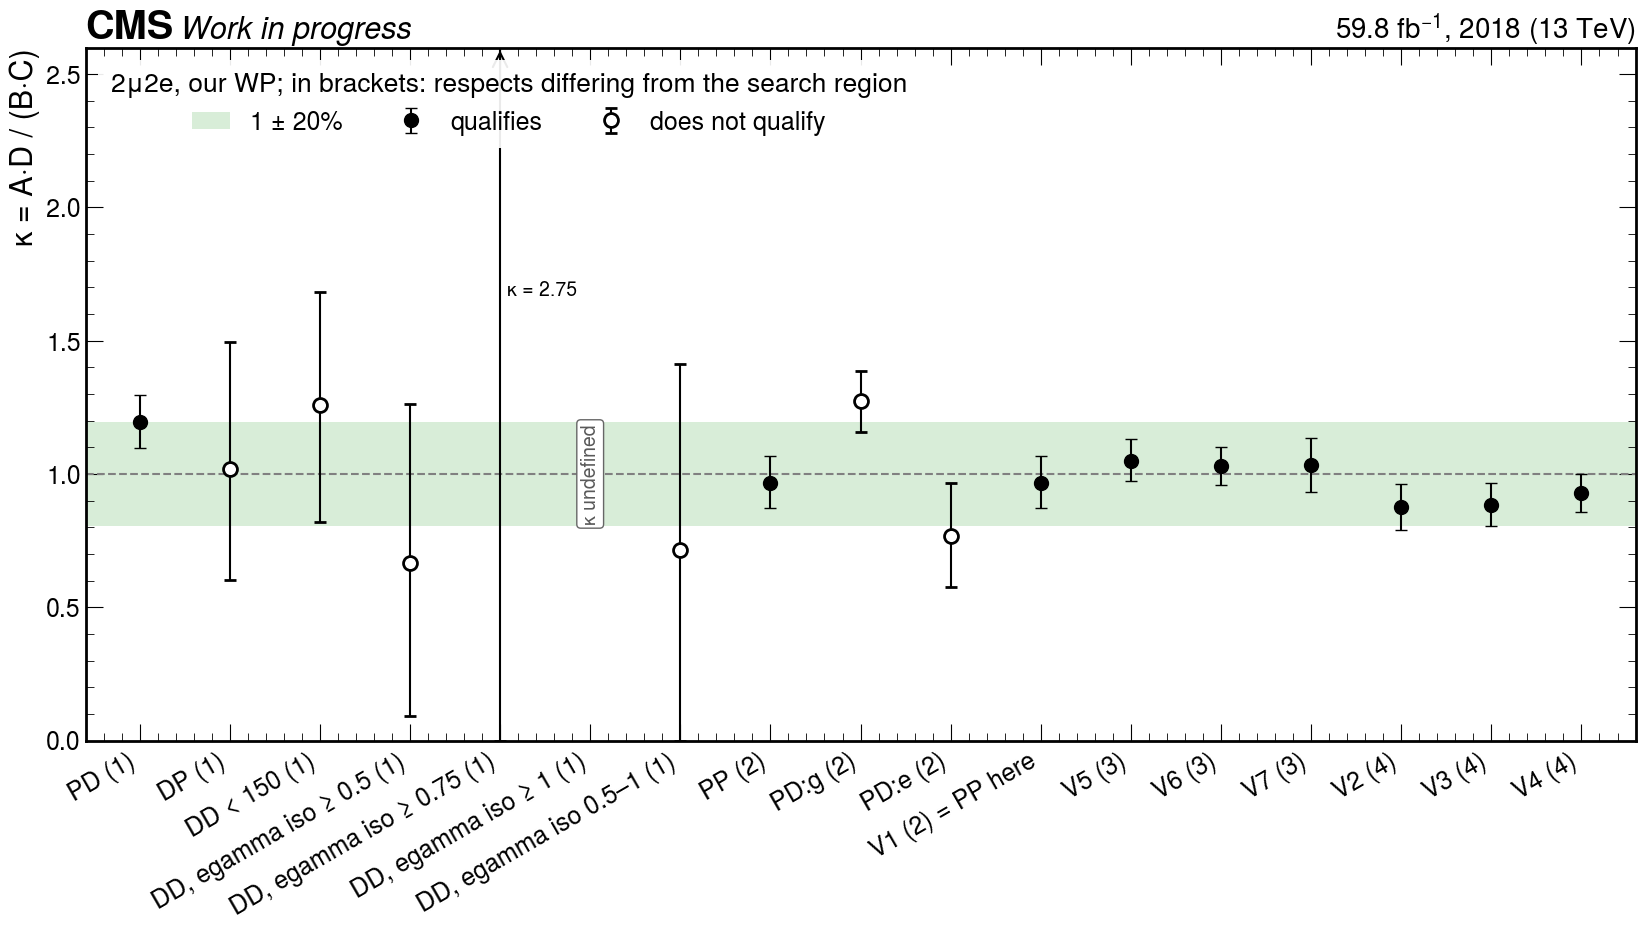

In [14]:
SYS = nl.systematic_table(d2, nl.our_vrs() + nl.DONGYUB_VRS)
display(nl.systematic_view(SYS))
SYST, SYST_FROM = nl.closure_systematic(SYS)
QUAD, _ = nl.closure_systematic(SYS, "quadrature")
ALT, ALT_FROM = nl.closure_systematic(SYS, qualifying=False)
EST = nl.kappa_row(d2, nl.SR, NOMINAL)
SYS50 = nl.systematic_table(d2, nl.our_vrs() + nl.DONGYUB_VRS, max_precision=0.5)
S50, S50_FROM = nl.closure_systematic(SYS50)
print(f"rule: {nl.pct(SYST)} from {SYST_FROM}; quadrature {nl.pct(QUAD)}; no precision cut {nl.pct(ALT)} from {ALT_FROM}; "
      f"precision cut 50% {nl.pct(S50)} from {S50_FROM}")
print(f"estimate: {EST['B C/D']:.1f} ± {EST['B C/D err']:.1f} (stat.) ± {EST['B C/D'] * SYST:.1f} (syst.) events")
points, labels = npl.table_points(SYS)
SAME_AS_PP = nl.same_regions(SYS, "PP")
labels = [f"{r} ({n})" + (" = PP here" if r in SAME_AS_PP else "") for r, n in zip(labels, SYS["n differences"])]
fig = npl.kappa_points_figure(points, labels, "2μ2e, our WP; in brackets: respects differing from the search region",
                              "nominal_kappa_systematic", band=SYST, band_label=f"1 ± {nl.pct(SYST)}", ylim=(0, 2.6),
                              hollow_label="does not qualify", filled_label="qualifies", width=20)
plt.show()

## 9. Cross-check: the three borrowed-factor routes

`estimate.ipynb` estimated A of DD three more ways, each by borrowing a ratio from PD per DSA class
and summing: B × (A/B), C × (A/C) and D × (A/D) give 61.3 ± 8.0, 59.7 ± 15.6 and 71.7 ± 15.3 events. Their spread
is not a systematic uncertainty: they share DD's sidebands with the direct estimate, and each
assumes that a ratio of PD transfers to DD. The B route holds if A/B itself transfers from PD to
DD. A/B of PD is κ_PD × C/D of PD, and DD's C/D is 0.73 -0.22 +0.31 times PD's (section 7e), so with DD's own
C/D the B route's 61 events require κ_DD = 1.34. The C and D routes likewise assume that
A/C and A/D transfer. The direct estimate and the B route differ by 16 events, 0.9 of the combined
statistical and systematic uncertainty of the direct estimate.

If the search plane's κ were PD's, A would be 1.20 × 45.7 ≈ 55 events, or
1.24 × 33.0 + 0.73 × 13.1 ≈ 51 with PD's κ per DSA class applied to DD's prediction per class; 61
assumes more than that.

The earlier notebooks made the B route the headline and the direct estimate a cross-check. This
one does the opposite: every qualifying validation region's κ lies within 20% of one at our
working point, and the largest deviation, PD at 2.0 standard deviations, is carried by
the systematic.

In [15]:
display(el.routes_table(d2, WINDOWS))
display(el.class_factors_table(d2, WINDOWS[:1]))

,window,DD B/C/D,direct B C/D,B x A/B per class,B x A/B inclusive,C x A/C per class,C x A/C inclusive,D x A/D per class,D x A/D inclusive,DD A observed
0,M >= 150,78/17/29,45.7 ± 14.9,61.3 ± 8.0,74.8 ± 9.0,59.7 ± 15.6,65.8 ± 16.5,71.7 ± 15.3,89.9 ± 17.5,blind
1,150-300,52/11/26,22.0 ± 8.5,41.2 ± 6.6,52.9 ± 7.7,39.2 ± 12.7,42.6 ± 13.2,64.8 ± 14.4,78.4 ± 16.2,blind
2,M >= 300,26/6/3,52.0 ± 38.2,18.6 ± 4.2,20.3 ± 4.4,20.8 -9.2 +9.7,23.2 ± 10.1,6.0 ± 4.7,10.4 ± 6.2,blind


,window,class,DD B/C/D,PD A/B/C/D,A/B PD,A/C PD,A/D PD,C/D PD,C/D DD,C/D DD over PD
0,M >= 150,dsa0,44/12/16,1253/1203/301/359,1.04 ± 0.04,4.16 -0.27 +0.29,3.49 -0.21 +0.22,0.84 -0.07 +0.07,0.75 -0.27 +0.43,0.89 -0.34 +0.51
1,M >= 150,dsa1+,34/5/13,90/198/46/74,0.45 -0.06 +0.07,1.96 -0.35 +0.43,1.22 -0.19 +0.22,0.62 -0.12 +0.14,0.38 -0.19 +0.35,0.62 -0.34 +0.57
2,M >= 150,all,78/17/29,1343/1401/347/433,0.96 ± 0.04,3.87 -0.23 +0.25,3.10 -0.17 +0.18,0.80 -0.06 +0.06,0.59 -0.17 +0.24,0.73 -0.22 +0.31


## 10. What opening 150–300 GeV of the search plane would and would not settle

The direct test of κ in the search plane is to open A of DD in a window where the signal is small.
The background predicted there (direct, and B route):

* 150–200 GeV: 10.5 ± 5.4 (B route 23.9 ± 5.3);
* 200–300 GeV: 12.0 ± 7.0 (B route 17.7 ± 4.3);
* 150–300 GeV: 22.0 ± 8.5 (B route 41.2 ± 6.6).

The two predictions for 150–300 GeV differ by a factor 1.9: the direct one uses DD's own
C/D in the window (52/11/26 events in B/C/D), the B route uses PD's A/B. Their ratio is the
product of two factors. The first is PD's κ per DSA class weighted by the search plane's B,
Σ_c B_DD,c (A/B)_PD,c ÷ (B_DD (C/D)_PD), 1.02 here; it is close to one although PD's κ
per class in the window is not, 1.39 ± 0.14 (`dsa0`) and 0.70 -0.19 +0.20 (`dsa1+`), because DD's B
in the window holds 25 and 27 events of the two classes and the two deviations
nearly cancel. The second is the sideband ratio (C/D)_PD / (C/D)_DD, 1.84 (the inverse of
the 0.54 -0.19 +0.28 of section 7e). The factor between the predictions is therefore almost all sideband
ratio.
A count near the first prediction would say that DD's own sidebands are right there; one near the
second, that the direct route under-predicts the window. The two predictions are 1.8
standard deviations apart if treated as independent, about 2.2 once the shared B is
accounted for (both scale with DD's B, with different factors), so the window can tell them apart, but not sharply. κ of DD in the
window would be measured to about 44% (21% from A's count alone, the
rest from B, C and D), which separates 1.0 from 1.9 but not from 1.20, and could not
qualify under the 20% criterion of the rule of section 8; and section 7d shows that κ
changes with the mass, so the window's κ is not the search region's. 150–200 GeV alone
would measure it to about 60%. The window is the only direct test there is; it is
not a sharp one.

The price is signal. Of the 90 2μ2e signal points, the 15 with a 200 GeV mediator put
45%–71% of their search-region yield in 150–200 GeV and 97%–100% in 150–300 GeV (yields
0.00–0.56 events at the stored cross sections of section 7f; below 150 GeV, in the already-open
DD validation region, they put a further 0.0%–2.2% of that yield, the column "below / yield" of
the table). The heavier points (500, 800, 1000 GeV) put at most
5.6% in 150–300 GeV; the 800 GeV, 0.25 GeV, 0.25 mm point, for example, has 58.8
events, 0.0% of them below 300 GeV and 97.4% at ≥ 600 GeV. Opening 150–300 GeV ends the
200 GeV search; opening 150–200 GeV costs about half of it. In absolute terms the loss is small:
at the stored cross sections the 200 GeV points put at most 0.56 events in 150–300 GeV,
on a predicted background of 22 there (yields scale with the cross section, the
shares above do not). The decision is the group's.

The table also lists the 100 and 150 GeV mediators. These masses are outside the range the
analysis targets (the group's grid of interest starts at 200 GeV) and are kept in the table for
completeness. For them much or most of the signal in A of DD sits below 150 GeV (86–98% at 100 GeV, 39–100% at 150 GeV),
so DD below 150 GeV, used here as a validation region, would be signal-contaminated for those
hypotheses.

The first table under the background predictions gives, per mediator mass, the range of the shares
and of the yields; the second, per point, the yield in A of DD at M ≥ 150 GeV in events, its share
per mass bin, and the yield below 150 GeV in events ("below [events]") and as a share of the
search-region yield ("below / yield").

*How to read the figure:* one bar per signal point (the 15 points with a 200 GeV mediator and
the 6 other points of `estimate.ipynb`), split into the share of its search-region
yield in each mass bin; the label gives the mediator mass, dark-photon mass and cτ, and the yield
in brackets (simulation).

,window,DD B/C/D,direct B C/D,B x A/B per class,DD A observed
0,150-200,28/6/16,10.5 ± 5.4,23.9 ± 5.3,blind
1,200-300,24/5/10,12.0 ± 7.0,17.7 ± 4.3,blind
2,150-300,52/11/26,22.0 ± 8.5,41.2 ± 6.6,blind


90 2mu2e signal points; share of the search-region yield per mass bin, min-max per mediator mass, and the yields in A of DD above and below 150 GeV in events


,mediator mass [GeV],points,150-200,200-300,150-300,>=600,"yield, M ≥ 150 [events]","yield, M < 150 [events]"
0,100,15,0–100%,0–100%,97–100%,0–0%,0.00–0.02,0.00–0.45
1,150,15,80–100%,0–19%,99–100%,0–0%,0.00–3.36,0.00–2.68
2,200,15,45–71%,29–53%,97–100%,0–0%,0.00–0.56,0.00–0.00
3,500,15,0–0%,0–5%,0–5%,2–17%,0.01–14.86,0.00–0.00
4,800,15,0–0%,0–6%,0–6%,93–100%,0.05–63.10,0.00–0.00
5,1000,15,0–0%,0–0%,0–0%,94–100%,0.00–2.05,0.00–0.00


,point,yield [events],150-200,200-300,300-400,400-600,>=600,150-300,below [events],below / yield
2,2Mu2E_1000GeV_0p25GeV_0p2mm,1.480,0.000,0.000,0.001,0.006,0.993,0.000,0.000,0.000
7,2Mu2E_1000GeV_1p2GeV_0p96mm,2.051,0.000,0.000,0.002,0.017,0.980,0.000,0.000,0.000
45,2Mu2E_200GeV_0p25GeV_0p01mm,0.009,0.508,0.492,0.000,0.000,0.000,1.000,0.000,0.004
46,2Mu2E_200GeV_0p25GeV_0p1mm,0.109,0.521,0.478,0.002,0.000,0.000,0.998,0.000,0.003
47,2Mu2E_200GeV_0p25GeV_10p0mm,0.117,0.459,0.521,0.020,0.000,0.000,0.980,0.000,0.002
48,2Mu2E_200GeV_0p25GeV_1p0mm,0.563,0.475,0.517,0.007,0.001,0.000,0.992,0.001,0.003
49,2Mu2E_200GeV_0p25GeV_5p0mm,0.231,0.459,0.530,0.010,0.001,0.000,0.989,0.001,0.002
50,2Mu2E_200GeV_1p2GeV_0p048mm,0.001,0.625,0.375,0.000,0.000,0.000,1.000,0.000,0.000
51,2Mu2E_200GeV_1p2GeV_0p48mm,0.041,0.543,0.453,0.002,0.002,0.000,0.996,0.000,0.010
52,2Mu2E_200GeV_1p2GeV_24p0mm,0.123,0.471,0.515,0.012,0.001,0.000,0.987,0.001,0.007


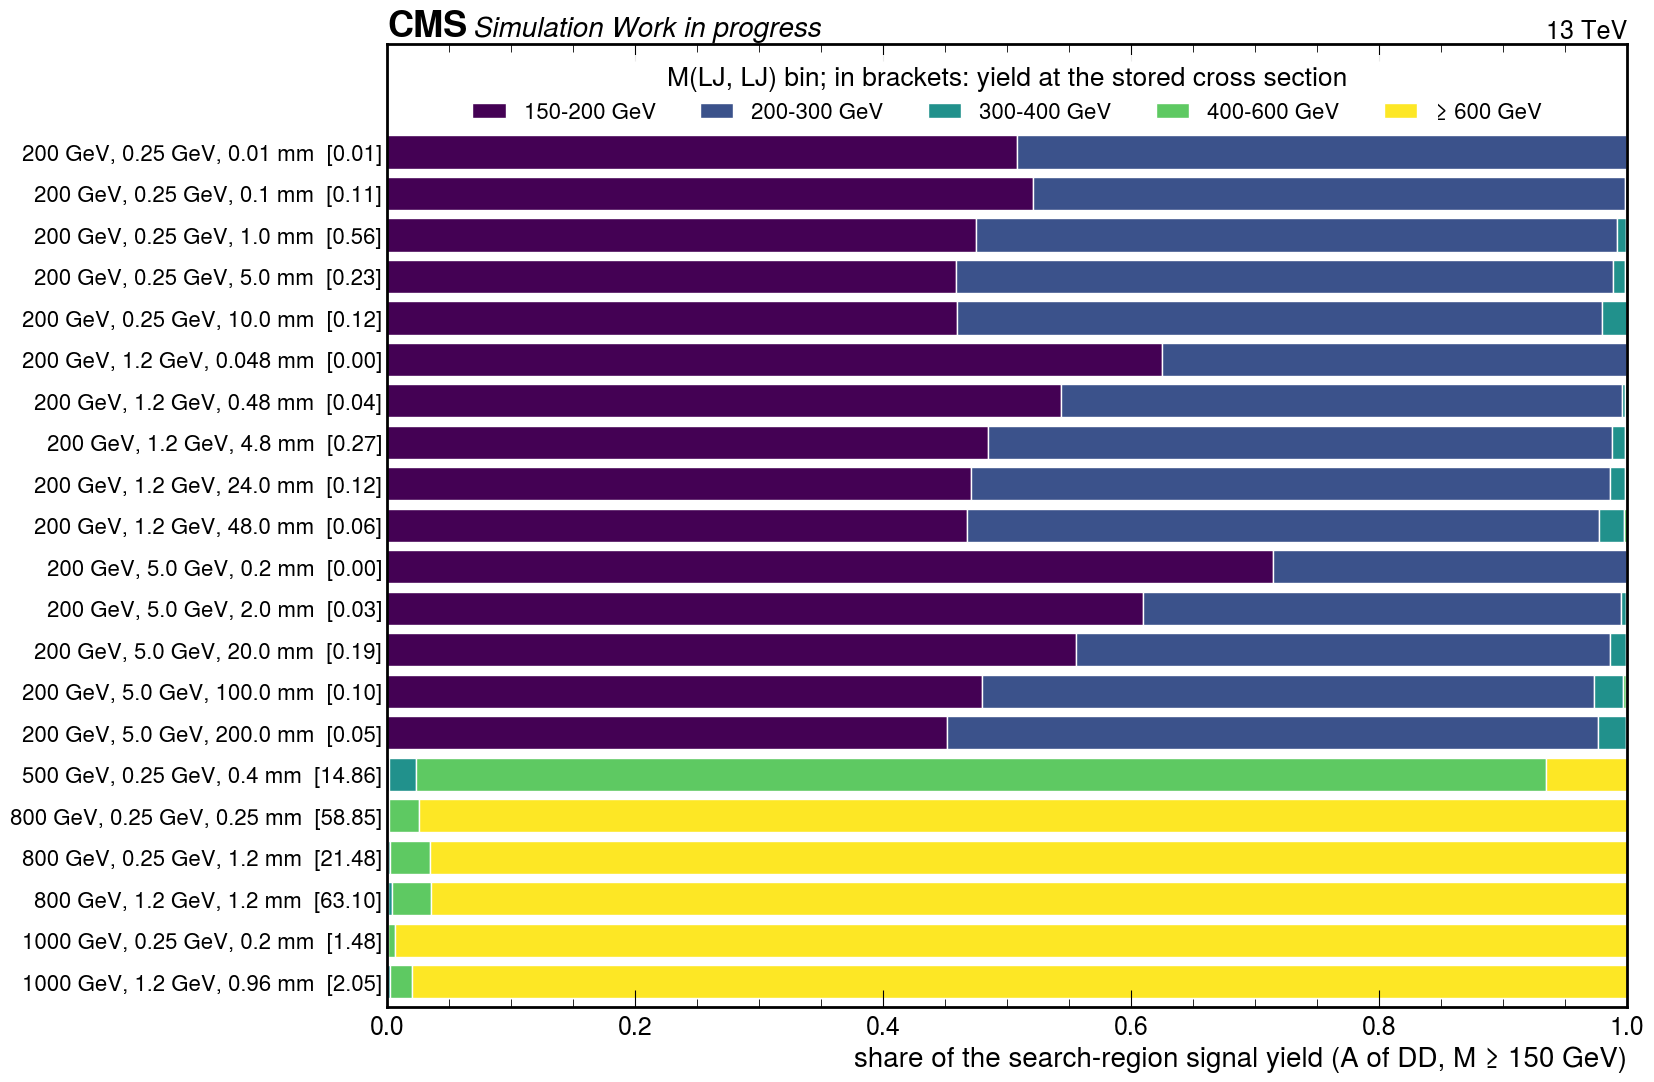

In [16]:
OPEN = [(label, bl.bin_cfg(NOMINAL, lo, hi)) for label, (lo, hi) in (("150-200", (150.0, 200.0)), ("200-300", (200.0, 300.0)), ("150-300", (150.0, 300.0)))]
display(el.routes_table(d2, OPEN)[["window", "DD B/C/D", "direct B C/D", "B x A/B per class", "DD A observed"]])
NAMES = sorted(os.path.basename(p)[: -len(".coffea")] for p in tl.sample_paths(BASE, "signal")
               if os.path.basename(p).startswith("2Mu2E_"))
SIGNAL = nl.signal_share_table(bl.signal_profiles(BASE, NAMES, "2mu2e", NOMINAL, plane="DD", region="A"))
print(f"{len(SIGNAL)} 2mu2e signal points; share of the search-region yield per mass bin, min-max per mediator mass, "
      "and the yields in A of DD above and below 150 GeV in events")
display(nl.share_summary(SIGNAL))
SHOWN = SIGNAL[SIGNAL["point"].str.startswith("2Mu2E_200GeV_") | SIGNAL["point"].isin(bl.SIGNAL_POINTS["2mu2e"])]
display(SHOWN.assign(**{"below / yield": SHOWN["below"] / SHOWN["yield"]})
        .rename(columns={"yield": "yield [events]", "below": "below [events]"}).round(3))
fig = npl.signal_share_figure(SHOWN.reset_index(drop=True))
plt.show()

## 11. 4μ in one section

In 4μ both LJs are muon LJs. The planes name the leading LJ (the one with the larger transverse
momentum) first, and each LJ is prompt or displaced by its pixel hits, as the muon LJ of 2μ2e. The
classes `dsaN:subdsaM` of the first table count the DSA muons in the leading (N) and the subleading
(M) muon LJ. The 4μ hidden box covers A above 150 GeV in DD and also in DP and PD, where the
signal is large too; those rows print "blind".

The search plane holds 2/1/3/3 events in A/B/C/D below 150 GeV and 3/0/0 in B/C/D above it: no
informative κ of the search plane can be measured (below 150 GeV it is 2.0 -2.0 +5.4), and no B·C/D
exists above 150 GeV (C and D are empty). Six count-limited readings come from the open
neighbouring regions, as in `estimate.ipynb` (section 5.2), with one change. Three take B of DD
above 150 GeV times A/B of a plane: for PP, A/B above 150 GeV, which is open (0.76 -0.06 +0.07), the same
mass window as the search region; for DP and PD, whose A is hidden there, A/B below 150 GeV. PP's
A/B is 1.66 times higher above 150 GeV than below (0.46 -0.03 +0.03), which suggests that the
DP and PD readings are biased low. The other three take A of DD below 150 GeV times the
above/below-150 GeV ratio of an open region of a neighbouring plane. The six read 1.1–2.3
events, median 1.7, each with a 58–78% statistical error: the 4μ background is uncertain
by a factor 2.1 between the lowest and the highest reading.

What that costs: the expected 95% CL upper limit on the signal count, the limit of a counting
experiment with a known background b (`estimate_lib.counting_limit`) at n equal to the median of a
Poisson distribution of mean b, is 4.1 for b = 1.10 (the lowest reading, median n = 1); 3.9 for b = 1.67 (the median, median n = 1); 4.7 for b = 2.31 (the highest reading, median n = 2). Over the readings' central values the expected limit
moves by 20% (3.9–4.7); allowing each reading its own statistical error, b from
0.67 to 4.17 (a factor 2.5 either side of the median, which covers each reading's own
statistical error), it moves from 3.0 to 5.8, a factor 1.9. The expected limit is not monotonic in b, because the median count steps in integers: it falls from 4.1 at b = 1.10 to 3.9 at b = 1.67, where the median count is still 1. The tables below give the
limit at these five values of b.

Of the open DD events, 0 have both muon LJs made only of DSA muons. That was the
signature of the instrumental background seen in July 2026 before the cosmic and spread cuts were
added: events whose two muon LJs were made only of DSA muons, back-to-back, consistent with cosmic
rays. This statement is about the open sidebands; an artefact that is isolated and back-to-back
would sit in A, which the sidebands cannot test. What addresses it is the cosmic and spread cuts:
the cut on the opening angle between the two muons, cos α > −0.99, and the cuts on the spread of the
muons' transverse and longitudinal impact parameters within an LJ.

Dongyub Lee's 4μ regions (quoted from his slides): the isolation × isolation plane (the plane of
the two LJs' isolations, with |Δφ| as an event cut) fails (4.66 ± 0.54), the muon-isolation ×
|Δφ| plane closes (1.06 ± 0.18) but its κ runs over 0.3–1.3 below 150 GeV and
0.75 to above 2 above as the isolation boundary moves. Nothing more can be done with these
counts.

In [17]:
HIGH4, LOW4 = ("M >= 150", NOMINAL), ("M < 150", LOW)
display(el.count_grid(d4, [LOW4, HIGH4], "DD", [f"dsa{a}:subdsa{b}" for a in ("0", "1", "2+") for b in ("0", "1", "2+")]))
print("B of the search plane above 150 GeV times A/B below 150 GeV of the planes whose A is open there (the form of estimate.ipynb)")
display(el.sideband_transfer_table(d4, HIGH4, LOW4))
print("A of the DD plane below 150 GeV times the above/below-150 GeV ratio of the open neighbouring regions")
display(el.mass_transfer_table(d4, HIGH4, LOW4))
READ4 = nl.fourmu_readings(d4, NOMINAL, LOW)
print("the six readings used here (PP's A/B taken above 150 GeV, where it is open)")
display(pd.DataFrame([{"reading": label, "estimate of DD A (M >= 150)": tl.fmt(k, 2)} for label, k in READ4]))
B4 = nl.fourmu_b_scan(READ4)["b"]
print("expected 95% CL upper limit on the signal count at the median of the readings divided by the factor, the lowest "
      "reading, the median, the highest and the median times the factor")
display(pd.DataFrame([{"b": f"{b:.2f}", "median n": n, "expected limit": f"{lim:.2f}"}
                      for b, (lim, n) in ((b, nl.expected_counting_limit(b)) for b in B4)]))
print("95% CL upper limit on a signal count for n observed events and the same backgrounds")
display(el.counting_limit_table((0, 1, 2), [round(b, 2) for b in B4]))

,window,region,total,dsa0:subdsa0,dsa0:subdsa1,dsa0:subdsa2+,dsa1:subdsa0,dsa1:subdsa1,dsa1:subdsa2+,dsa2+:subdsa0,dsa2+:subdsa1,dsa2+:subdsa2+
0,M < 150,A,2,0,0,0,2,0,0,0,0,0
1,M < 150,B,1,0,0,0,0,1,0,0,0,0
2,M < 150,C,3,0,0,0,0,2,0,1,0,0
3,M < 150,D,3,1,0,0,1,1,0,0,0,0
4,M >= 150,A,blind,blind,blind,blind,blind,blind,blind,blind,blind,blind
5,M >= 150,B,3,0,1,0,1,0,0,0,1,0
6,M >= 150,C,0,0,0,0,0,0,0,0,0,0
7,M >= 150,D,0,0,0,0,0,0,0,0,0,0


B of the search plane above 150 GeV times A/B below 150 GeV of the planes whose A is open there (the form of estimate.ipynb)


,reference plane,"A, B (M < 150)",A/B (M < 150),A/B (M >= 150),DD B (M >= 150),estimate of DD A (M >= 150)
0,DP,"30, 39",0.77 -0.18 +0.24,blind,3,2.31 ± 1.51
1,PD,"15, 41",0.37 -0.11 +0.15,blind,3,1.10 -0.71 +0.78
2,PP,"332, 725",0.46 -0.03 +0.03,0.76 -0.06 +0.07,3,1.37 ± 0.80


A of the DD plane below 150 GeV times the above/below-150 GeV ratio of the open neighbouring regions


,reference region,N (M >= 150),N (M < 150),ratio,DD A (M < 150),estimate of DD A (M >= 150)
0,PP A,264,332,0.80 -0.07 +0.07,2,1.59 ± 1.13
1,DP B,34,39,0.87 -0.20 +0.26,2,1.74 ± 1.34
2,PD B,25,41,0.61 -0.15 +0.20,2,1.22 ± 0.95


...

,reading,estimate of DD A (M >= 150)
0,"B of DD × A/B of PP, same window",2.28 ± 1.33
1,B of DD × A/B of DP below the window,2.31 ± 1.51
2,B of DD × A/B of PD below the window,1.10 -0.71 +0.78
3,A of DD below × A of PP between the windows,1.59 ± 1.13
4,A of DD below × B of DP between the windows,1.74 ± 1.34
5,A of DD below × B of PD between the windows,1.22 ± 0.95


expected 95% CL upper limit on the signal count at the median of the readings divided by the factor, the lowest reading, the median, the highest and the median times the factor


,b,median n,expected limit
0,0.67,0,3.00
1,1.10,1,4.08
2,1.67,1,3.90
3,2.31,2,4.69
4,4.17,4,5.80


95% CL upper limit on a signal count for n observed events and the same backgrounds


,observed,b = 0.67,b = 1.1,b = 1.67,b = 2.31,b = 4.17
0,0,3.00,3.00,3.00,3.00,3.00
1,1,4.26,4.07,3.90,3.75,3.51
2,2,5.67,5.34,4.99,4.69,4.15


## 12. Summary and to-do list

* The 2μ2e background in the one-bin search region is **46 ± 15 (stat.) ± 9 (syst.) events**, the search plane's
  own B·C/D; a Poisson bootstrap of B, C and D gives the 68% interval 32–63. The systematic
  uncertainty is 20% by the rule of section 8 (set by PD); −20%/+31% if the upper side is taken from the largest reweighted reading (the reweighting by egamma type, 1.31), which this notebook recommends; the choice is the group's.
* A caveat the rule does not cover: in DD the LJ-pair mass correlates with both ABCD variables, and
  the estimate made separately in 150–300 GeV and above 300 GeV sums to 74 events, 1.62
  times the one-bin estimate (bootstrap 16th/50th/84th percentiles of the ratio 1.15/1.59/2.70, below
  one in 3% of the toys). The open planes cannot test it (ratio 1.01–1.03), and it
  rests on 3 events in D above 300 GeV; a search region binned in mass, or more data, resolves it.
* κ closes in PP (0.97 ± 0.10). Dongyub Lee's seven regions agree between the two codes at his working
  point (to the printed digit in 6 of 7); they test the method on populations with a prompt
  muon LJ. At our working point PD, V2 and V3 miss one at 68% (V4 touches it). From his working point to ours κ falls by 0.08–0.14
  in V2–V4, 1.7–2.4 standard deviations of the shift.
* Among the regions measured to 20% or better, the largest deviation is in PD (1.20 ± 0.10), carried by its photon-only egamma LJs (PD:g, 1.27 ± 0.12); DD's sidebands are as photon-rich as PD's.
  PD's C/D does not transfer to DD: DD over PD is 0.73 -0.22 +0.31.
* The open regions with both LJs displaced are imprecise: DD below 150 GeV (1.26 ± 0.44) and the DD
  bands above 150 GeV (0.67, 2.75, undefined and 0.71 for egamma-LJ isolation ≥ 0.5, ≥ 0.75, ≥ 1 and 0.5–1); none of them is measured to 20% or better, so none can carry the systematic of section 8. DP, with only the muon LJ displaced, reads
  1.02 -0.41 +0.48.
* κ falls with the mass (2.9 standard deviations from 150–300 GeV to above 300 GeV, a split
  chosen after looking; the five-bin χ² against a constant κ is 3.9/4 in PP and 3.9/4 in
  PD). For a binned search region it is an effect of up to 33% per window.
* Signal at the stored cross sections: the DD bands above 150 GeV hold up to 53% signal (DD, egamma iso ≥ 0.75, 2Mu2E_800GeV_5p0GeV_5p0mm), the other three bands 41%–47%, which rules them out as validation regions for that reason too. In the regions that qualify for the rule the largest ratio is in A of PP, 18% from 2Mu2E_800GeV_0p25GeV_0p0025mm, whose search-region yield is 0.8 events. That point is a prompt one (cτ = 0.0025 mm), to which the displaced search is not sensitive (0.8 events in the search region), so its 18% in A of PP is not a contamination of the search. At the cross section the search can exclude for the reference point,
  its ratios are 26% of their stored-cross-section values.
* The B route (61 events) is the cross-check; it holds if A/B transfers from PD, which with DD's
  own C/D requires κ_DD = 1.34. With PD's κ itself, A would be 55 (51 per DSA
  class).
* Opening 150–300 GeV of the search plane would measure κ there to about 44%, not
  enough to qualify under the rule.
* 4μ: about 1.7 events (the median of six readings), uncertain by a factor 2.1 between the
  readings; the expected limit moves by 20% over their central values and by a factor 1.9
  (3.0–5.8) once each reading's own statistical error is allowed. Nothing more to do with these counts.

To do, for the group:

1. Fix the blinding box: Dongyub Lee's 6D histograms carry the data in the search region unblinded.
2. Dongyub to reproduce κ_PD from his 6D histograms, and to split his validation regions above
   150 GeV at 300 or 400 GeV.
3. State the criterion by which the working point is chosen.
4. Decide whether to open 150–300 GeV (or 150–200 GeV) of the search plane as a validation region.
5. Adopt the direct ABCD with the validation-region systematic as the convention.

## Appendix: reproducibility

The data are read only through `transfer_lib.summed_cubes(BASE, "data", prefix="abcd8d")`,
which sums the merged 8D histograms and sets the hidden box (iso0<0.25 iso1<0.5 mass>=150 dphi>=2.4 planes=[('2mu2e', ('displaced', 'displaced')), ('4mu', ('displaced', 'displaced')), ('4mu', ('displaced', 'prompt')), ('4mu', ('prompt', 'displaced'))]) to NaN before anything is
cached or returned; every projection touching a hidden cell is NaN and prints as "hidden". The
signal table of section 7f and the signal shares of section 10 read the signal histograms one point
at a time (`nominal_lib.signal_region_counts`, `binning_lib.signal_profiles`; simulation is never
hidden), and section 2 reads the summed background simulation (`transfer_lib.summed_cubes(BASE,
"bkg", prefix="abcd8d")`). Code: `nominal_lib.py` (validation
regions, the systematic rule, the working-point shift, the mass-split ratio and its bootstrap, the
plane histogram, the signal tables, the 4μ readings), `nominal_plots.py` (the figures),
`_build_nominal.py` (writes this notebook and computes every number in its text with the same
functions), `test_nominal_lib.py` (tests on synthetic histograms). On the LPC:
`python _build_nominal.py` then `jupyter nbconvert --to notebook --execute --inplace
nominal.ipynb` in `sidm_venv`.